# Predicting E-Commerce Delivery Delays Using Data Mining Techniques

**Team:** Raudhat Ramadhan Mwinyi and Given Kangwa   
**Instructor:** Prof. Innocent Nyalala  
**Dataset:** Brazilian E-Commerce Public Dataset by Olist  
**Primary technique:** Decision Tree Classification
**Additional technique:** Random Forest Classifier
## 1. Introduction

### Problem statement
Late e-commerce deliveries can reduce customer satisfaction and increase operational costs. This project investigates whether information available when an order is placed can help identify orders at risk of arriving after their estimated delivery date.

### Research question
**Can order-level information available at purchase time be used to classify an order as On Time or Delayed?**

### Objectives
1. Understand and inspect the original Olist datasets.
2. Integrate relevant tables into one record per eligible order.
3. Explore data quality, distributions, relationships and potential confounding factors.
4. Prepare a leakage-aware feature set.
5. Train and evaluate a Decision Tree against a majority-class baseline.
6. Conduct an additional Random Forest experiment and compare it with the required Decision Tree.
7. Interpret results and discuss business, ethical and scalability implications.

### Target definition
- `delivery_status = 0`: delivered on or before the estimated delivery date (On Time).
- `delivery_status = 1`: delivered after the estimated delivery date (Delayed).

Cancelled, unavailable and non-delivered orders are excluded from this binary delivered-order classification task. The model therefore does not predict cancellation or non-delivery.

## 2. How to run this notebook

Run from top to bottom using Python 3.10+ and an internet connection for KaggleHub dataset acquisition. Install dependencies in the VS Code terminal if needed:

```bash
pip install kagglehub pandas numpy matplotlib seaborn scipy scikit-learn jupyter ipykernel
```

The fixed random seed is `27`. Outputs are cleared in this revised copy; rerun all cells to regenerate current outputs.

## 3. Dataset acquisition and understanding

The Olist dataset contains nine CSV files. The next cells download and inspect all source files.

In [3]:
# If required, install dependencies in the VS Code terminal:
# pip install kagglehub pandas numpy matplotlib seaborn scipy scikit-learn jupyter ipykernel

In [4]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 27

In [5]:
import kagglehub
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Dataset directory:", path)

Dataset directory: C:\Users\USER\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2


In [6]:
import os

# List all downloaded files
for file in os.listdir(path):
    print(file)

olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [7]:
import pandas as pd
import glob
import os

csv_files = glob.glob(os.path.join(path, "*.csv"))

for file in csv_files:
    df = pd.read_csv(file)

    print(f"\nFile: {os.path.basename(file)}")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")
    print("-" * 50)


File: olist_customers_dataset.csv
Rows: 99441
Columns: 5
--------------------------------------------------

File: olist_geolocation_dataset.csv
Rows: 1000163
Columns: 5
--------------------------------------------------

File: olist_orders_dataset.csv
Rows: 99441
Columns: 8
--------------------------------------------------

File: olist_order_items_dataset.csv
Rows: 112650
Columns: 7
--------------------------------------------------

File: olist_order_payments_dataset.csv
Rows: 103886
Columns: 5
--------------------------------------------------

File: olist_order_reviews_dataset.csv
Rows: 99224
Columns: 7
--------------------------------------------------

File: olist_products_dataset.csv
Rows: 32951
Columns: 9
--------------------------------------------------

File: olist_sellers_dataset.csv
Rows: 3095
Columns: 4
--------------------------------------------------

File: product_category_name_translation.csv
Rows: 71
Columns: 2
--------------------------------------------------


In [8]:
# Load all nine original CSV files.
file_names = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}
datasets = {}
for key, filename in file_names.items():
    datasets[key] = pd.read_csv(os.path.join(path, filename), low_memory=False)
    print(f"{key}: {datasets[key].shape[0]:,} rows × {datasets[key].shape[1]} columns")

orders = datasets["orders"]
order_items = datasets["order_items"]
customers = datasets["customers"]
products = datasets["products"]
sellers = datasets["sellers"]
payments = datasets["payments"]
reviews = datasets["reviews"]
geolocation = datasets["geolocation"]
category_translation = datasets["category_translation"]

orders: 99,441 rows × 8 columns
order_items: 112,650 rows × 7 columns
customers: 99,441 rows × 5 columns
products: 32,951 rows × 9 columns
sellers: 3,095 rows × 4 columns
payments: 103,886 rows × 5 columns
reviews: 99,224 rows × 7 columns
geolocation: 1,000,163 rows × 5 columns
category_translation: 71 rows × 2 columns


In [9]:
# Inspect all source tables: columns, dimensions and missing values
for table_name, df in datasets.items():
    print(f"\\n{'=' * 72}\\n{table_name.upper()} | Shape: {df.shape}")
    print("Columns:", df.columns.tolist())
    missing = df.isna().sum().to_frame("Missing count")
    display(missing[missing["Missing count"] > 0])

\n========================================================================\nORDERS | Shape: (99441, 8)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,Missing count
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965


\n========================================================================\nORDER_ITEMS | Shape: (112650, 7)
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


,Missing count


\n========================================================================\nCUSTOMERS | Shape: (99441, 5)
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


,Missing count


... (8 outputs left out)

\n========================================================================\nGEOLOCATION | Shape: (1000163, 5)
Columns: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']


,Missing count


\n========================================================================\nCATEGORY_TRANSLATION | Shape: (71, 2)
Columns: ['product_category_name', 'product_category_name_english']


,Missing count


### 3.1 Source-table meaning, keys and relationships

The following table records the row meaning and common identifiers in the Olist relational dataset. Some tables use composite keys or do not have a simple unique primary key.

In [10]:
data_dictionary = pd.DataFrame([
    ["orders", "One customer order", "order_id", "customer_id → customers.customer_id"],
    ["order_items", "One item line within an order", "(order_id, order_item_id)", "order_id → orders; product_id → products; seller_id → sellers"],
    ["customers", "One customer record", "customer_id", "customer_unique_id links repeat customer identities"],
    ["products", "One product", "product_id", "product_category_name → category translation"],
    ["sellers", "One seller", "seller_id", "Referenced by order_items.seller_id"],
    ["payments", "One payment record/installment", "(order_id, payment_sequential)", "order_id → orders"],
    ["reviews", "One review record", "review_id (check uniqueness)", "order_id → orders"],
    ["geolocation", "One postal-code coordinate record", "No guaranteed simple unique key", "zip_code_prefix is a lookup key; multiple coordinates may exist"],
    ["category_translation", "One category translation", "product_category_name", "Maps product category names"]
], columns=["Source table", "Row meaning", "Primary key / uniqueness", "Foreign key / relationship"])
display(data_dictionary)

,Source table,Row meaning,Primary key / uniqueness,Foreign key / relationship
0,orders,One customer order,order_id,customer_id → customers.customer_id
1,order_items,One item line within an order,"(order_id, order_item_id)",order_id → orders; product_id → products; sell...
2,customers,One customer record,customer_id,customer_unique_id links repeat customer ident...
3,products,One product,product_id,product_category_name → category translation
4,sellers,One seller,seller_id,Referenced by order_items.seller_id
5,payments,One payment record/installment,"(order_id, payment_sequential)",order_id → orders
6,reviews,One review record,review_id (check uniqueness),order_id → orders
7,geolocation,One postal-code coordinate record,No guaranteed simple unique key,zip_code_prefix is a lookup key; multiple coor...
8,category_translation,One category translation,product_category_name,Maps product category names


**Integration decisions:** `orders` is the central table. Customer attributes are joined to orders. Order items and payments are aggregated to one row per `order_id` before merging, preventing multiple item/payment rows from multiplying order records.

Products, sellers, reviews, geolocation and category translations are inspected but are not merged as separate row-level tables in the initial model. Seller information contributes through the `unique_sellers` item summary. Reviews are excluded because they are generally created after delivery and are not valid purchase-time predictors. Detailed product, seller and geolocation attributes are possible future features only after an availability and leakage audit.

In [11]:
# Check the distribution of order statuses
print("Order status distribution:")
print(orders["order_status"].value_counts(dropna=False))

print("\nDelivery date availability by order status:")
print(
    orders.groupby("order_status")[
        "order_delivered_customer_date"
    ].apply(lambda x: x.isna().sum())
)

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Delivery date availability by order status:
order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64


In [12]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Calculate actual delivery time difference in days
orders["delivery_difference_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

print("Delivery difference summary:")
print(orders["delivery_difference_days"].describe())

print("\nOrders with actual delivery dates:")
print(orders["order_delivered_customer_date"].notna().sum())

Delivery difference summary:
count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delivery_difference_days, dtype: float64

Orders with actual delivery dates:
96476


In [13]:
# Keep only delivered orders with a valid actual delivery date
model_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Create target variable
model_orders["delivery_status"] = (
    model_orders["order_delivered_customer_date"] >
    model_orders["order_estimated_delivery_date"]
).astype(int)

# Replace numeric labels with readable labels for inspection
model_orders["delivery_status_label"] = (
    model_orders["delivery_status"]
    .map({0: "On Time", 1: "Delayed"})
)

print("Eligible orders:", len(model_orders))

print("\nDelivery status distribution:")
print(model_orders["delivery_status_label"].value_counts())

print("\nDelivery status percentages:")
print(
    model_orders["delivery_status_label"]
    .value_counts(normalize=True).mul(100).round(2)
)

Eligible orders: 96470

Delivery status distribution:
delivery_status_label
On Time    88644
Delayed     7826
Name: count, dtype: int64

Delivery status percentages:
delivery_status_label
On Time    91.89
Delayed     8.11
Name: proportion, dtype: float64


In [14]:
# Aggregate order items: one row per order
item_summary = order_items.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    average_item_price=("price", "mean"),
    unique_sellers=("seller_id", "nunique")
).reset_index()

print("Order item summary shape:", item_summary.shape)
print(item_summary.head())

Order item summary shape: (98666, 6)
                           order_id  item_count  total_price  total_freight  \
0  00010242fe8c5a6d1ba2dd792cb16214           1        58.90          13.29   
1  00018f77f2f0320c557190d7a144bdd3           1       239.90          19.93   
2  000229ec398224ef6ca0657da4fc703e           1       199.00          17.87   
3  00024acbcdf0a6daa1e931b038114c75           1        12.99          12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9           1       199.90          18.14   

   average_item_price  unique_sellers  
0               58.90               1  
1              239.90               1  
2              199.00               1  
3               12.99               1  
4              199.90               1  


In [15]:
# Aggregate payments: one row per order
payment_summary = payments.groupby("order_id").agg(
    total_payment=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
    payment_types=("payment_type", "nunique")
).reset_index()

# Most common payment type for each order
main_payment_type = (
    payments.groupby("order_id")["payment_type"]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index(name="main_payment_type")
)

payment_summary = payment_summary.merge(
    main_payment_type,
    on="order_id",
    how="left"
)

print("Payment summary shape:", payment_summary.shape)
print(payment_summary.head())

Payment summary shape: (99440, 5)
                           order_id  total_payment  max_installments  \
0  00010242fe8c5a6d1ba2dd792cb16214          72.19                 2   
1  00018f77f2f0320c557190d7a144bdd3         259.83                 3   
2  000229ec398224ef6ca0657da4fc703e         216.87                 5   
3  00024acbcdf0a6daa1e931b038114c75          25.78                 2   
4  00042b26cf59d7ce69dfabb4e55b4fd9         218.04                 3   

   payment_types main_payment_type  
0              1       credit_card  
1              1       credit_card  
2              1       credit_card  
3              1       credit_card  
4              1       credit_card  


In [16]:
# Start with eligible orders and retain the target
final_df = model_orders[
    ["order_id", "customer_id", "order_purchase_timestamp",
     "order_estimated_delivery_date", "delivery_status"]
].copy()

# Merge customer information
final_df = final_df.merge(
    customers[[
        "customer_id",
        "customer_city",
        "customer_state",
        "customer_zip_code_prefix"
    ]],
    on="customer_id",
    how="left"
)

# Merge item summary
final_df = final_df.merge(
    item_summary,
    on="order_id",
    how="left"
)

# Merge payment summary
final_df = final_df.merge(
    payment_summary,
    on="order_id",
    how="left"
)

print("Final dataset shape:", final_df.shape)
print("Unique orders:", final_df["order_id"].nunique())
print("\nFirst five rows:")
display(final_df.head())

Final dataset shape: (96470, 17)
Unique orders: 96470

First five rows:


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,total_freight,average_item_price,unique_sellers,total_payment,max_installments,payment_types,main_payment_type
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,0,sao paulo,SP,3149,1,29.99,8.72,29.99,1,38.71,1.0,2.0,voucher
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,0,barreiras,BA,47813,1,118.70,22.76,118.70,1,141.46,1.0,1.0,boleto
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,0,vianopolis,GO,75265,1,159.90,19.22,159.90,1,179.12,3.0,1.0,credit_card
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,0,sao goncalo do amarante,RN,59296,1,45.00,27.20,45.00,1,72.20,1.0,1.0,credit_card
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,0,santo andre,SP,9195,1,19.90,8.72,19.90,1,28.62,1.0,1.0,credit_card


In [17]:
# Check missing values in the integrated dataset
missing_summary = pd.DataFrame({
    "Missing Count": final_df.isnull().sum(),
    "Missing Percentage": (
        final_df.isnull().mean() * 100
    ).round(2)
})

print(missing_summary)

                               Missing Count  Missing Percentage
order_id                                   0                 0.0
customer_id                                0                 0.0
order_purchase_timestamp                   0                 0.0
order_estimated_delivery_date              0                 0.0
delivery_status                            0                 0.0
customer_city                              0                 0.0
customer_state                             0                 0.0
customer_zip_code_prefix                   0                 0.0
item_count                                 0                 0.0
total_price                                0                 0.0
total_freight                              0                 0.0
average_item_price                         0                 0.0
unique_sellers                             0                 0.0
total_payment                              1                 0.0
max_installments         

### Missing-value investigation and treatment

Missing actual delivery dates are expected for orders that were not delivered; these orders are excluded from this delivered-order classification. Missing item/payment summaries after aggregation may indicate absent source records or join mismatches and should be investigated rather than automatically treated as zero.

The one missing payment summary is estimated as item price plus freight. This is an assumption, not an observed payment value. Payment-related attributes are not selected as predictors in the current model. Missingness counts alone cannot establish whether data are MCAR, MAR or MNAR; that requires evidence about why values are missing.

In [18]:
print("Orders without item information:",
      final_df["item_count"].isna().sum())

print("Orders without payment information:",
      final_df["total_payment"].isna().sum())

print("\nOrders with missing item details:")
display(final_df[final_df["item_count"].isna()].head())

print("\nOrders with missing payment details:")
display(final_df[final_df["total_payment"].isna()].head())

Orders without item information: 0
Orders without payment information: 1

Orders with missing item details:


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,total_freight,average_item_price,unique_sellers,total_payment,max_installments,payment_types,main_payment_type



Orders with missing payment details:


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,total_freight,average_item_price,unique_sellers,total_payment,max_installments,payment_types,main_payment_type
29809,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,2016-09-15 12:16:38,2016-10-04,1,sao joaquim da barra,SP,14600,3,134.97,8.49,44.99,1,NaN,NaN,NaN,NaN


In [19]:
# Extract features from purchase timestamp
final_df["purchase_year"] = (
    final_df["order_purchase_timestamp"].dt.year
)

final_df["purchase_month"] = (
    final_df["order_purchase_timestamp"].dt.month
)

final_df["purchase_day"] = (
    final_df["order_purchase_timestamp"].dt.day
)

final_df["purchase_day_of_week"] = (
    final_df["order_purchase_timestamp"].dt.dayofweek
)

final_df["purchase_hour"] = (
    final_df["order_purchase_timestamp"].dt.hour
)

# Estimated delivery window in days
final_df["estimated_delivery_days"] = (
    final_df["order_estimated_delivery_date"]
    - final_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

display(final_df.head())

,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,...,total_payment,max_installments,payment_types,main_payment_type,purchase_year,purchase_month,purchase_day,purchase_day_of_week,purchase_hour,estimated_delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,0,sao paulo,SP,3149,1,29.99,...,38.71,1.0,2.0,voucher,2017,10,2,0,10,15.544063
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,0,barreiras,BA,47813,1,118.70,...,141.46,1.0,1.0,boleto,2018,7,24,1,20,19.137766
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,0,vianopolis,GO,75265,1,159.90,...,179.12,3.0,1.0,credit_card,2018,8,8,2,8,26.639711
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,0,sao goncalo do amarante,RN,59296,1,45.00,...,72.20,1.0,1.0,credit_card,2017,11,18,5,19,26.188819
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,0,santo andre,SP,9195,1,19.90,...,28.62,1.0,1.0,credit_card,2018,2,13,1,21,12.112049


In [20]:
# Handle the single missing payment record
final_df["total_payment"] = final_df["total_payment"].fillna(
    final_df["total_price"] + final_df["total_freight"]
)

final_df["max_installments"] = final_df["max_installments"].fillna(0)

final_df["payment_types"] = final_df["payment_types"].fillna(0)

final_df["main_payment_type"] = final_df["main_payment_type"].fillna(
    "unknown"
)

print("Remaining missing values:")
print(final_df.isnull().sum().sum())

Remaining missing values:
0


In [21]:
print("Dataset shape:", final_df.shape)

print("\nMissing values:")
print(final_df.isnull().sum().sum())

print("\nDuplicate orders:")
print(final_df["order_id"].duplicated().sum())

print("\nTarget distribution:")
print(final_df["delivery_status"].value_counts())

Dataset shape: (96470, 23)

Missing values:
0

Duplicate orders:
0

Target distribution:
delivery_status
0    88644
1     7826
Name: count, dtype: int64


In [22]:
assert final_df["order_id"].is_unique, "Expected exactly one row per order."
assert set(final_df["delivery_status"].dropna().unique()).issubset({0, 1})
print("One row per order:", final_df["order_id"].is_unique)
print("Target values:", sorted(final_df["delivery_status"].dropna().unique()))
for col in ["item_count", "total_price", "total_freight", "estimated_delivery_days"]:
    print(f"Negative values in {col}:", (final_df[col] < 0).sum())

One row per order: True
Target values: [np.int64(0), np.int64(1)]
Negative values in item_count: 0
Negative values in total_price: 0
Negative values in total_freight: 0
Negative values in estimated_delivery_days: 0


In [23]:
final_df.to_csv("olist_integrated_dataset.csv", index=False)

print("Integrated dataset saved successfully!")

Integrated dataset saved successfully!


EXPLORATORY DATA ANALYSIS(EDA)

In [24]:
# Select numerical columns
numerical_columns = [
    "item_count",
    "total_price",
    "total_freight",
    "average_item_price",
    "unique_sellers",
    "total_payment",
    "max_installments",
    "payment_types",
    "customer_zip_code_prefix",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "purchase_day_of_week",
    "purchase_hour",
    "estimated_delivery_days"
]

# Generate descriptive statistics
descriptive_stats = final_df[numerical_columns].describe().T

display(descriptive_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
item_count,96470.0,1.14,0.54,1.00,1.00,1.00,1.00,21.00
total_price,96470.0,137.04,209.05,0.85,45.90,86.50,149.90,13440.00
total_freight,96470.0,22.79,21.56,0.00,13.85,17.17,24.02,1794.96
average_item_price,96470.0,125.23,189.70,0.85,41.90,79.00,139.90,6735.00
unique_sellers,96470.0,1.01,0.12,1.00,1.00,1.00,1.00,5.00
total_payment,96470.0,159.86,218.82,9.59,61.88,105.28,176.33,13664.08
max_installments,96470.0,2.93,2.71,0.00,1.00,2.00,4.00,24.00
payment_types,96470.0,1.02,0.15,0.00,1.00,1.00,1.00,2.00
customer_zip_code_prefix,96470.0,35199.20,29839.79,1003.00,11355.00,24436.00,59056.00,99980.00
purchase_year,96470.0,2017.54,0.50,2016.00,2017.00,2018.00,2018.00,2018.00


`describe()` provides count, mean, standard deviation, minimum, quartiles and maximum. The following cell adds the mode, which is not included in `describe()`.

In [25]:
numeric_summary = final_df[numerical_columns].describe().T
numeric_summary["mode"] = [
    final_df[col].mode(dropna=True).iloc[0]
    if not final_df[col].mode(dropna=True).empty else np.nan
    for col in numerical_columns
]
display(numeric_summary.round(3))

,count,mean,std,min,25%,50%,75%,max,mode
item_count,96470.0,1.142,0.539,1.000,1.00,1.000,1.000,21.000,1.000
total_price,96470.0,137.040,209.053,0.850,45.90,86.500,149.900,13440.000,59.900
total_freight,96470.0,22.786,21.560,0.000,13.85,17.170,24.020,1794.960,15.100
average_item_price,96470.0,125.232,189.704,0.850,41.90,79.000,139.900,6735.000,59.900
unique_sellers,96470.0,1.014,0.124,1.000,1.00,1.000,1.000,5.000,1.000
total_payment,96470.0,159.855,218.820,9.590,61.88,105.280,176.330,13664.080,77.570
max_installments,96470.0,2.928,2.713,0.000,1.00,2.000,4.000,24.000,1.000
payment_types,96470.0,1.023,0.149,0.000,1.00,1.000,1.000,2.000,1.000
customer_zip_code_prefix,96470.0,35199.197,29839.791,1003.000,11355.00,24436.000,59056.000,99980.000,22790.000
purchase_year,96470.0,2017.544,0.504,2016.000,2017.00,2018.000,2018.000,2018.000,2018.000


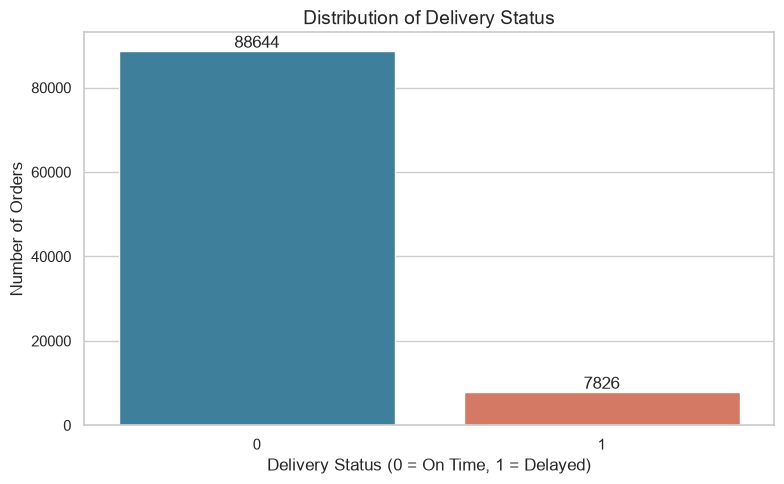

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=final_df,
    x="delivery_status",
    hue="delivery_status",
    palette=["#2E86AB", "#E76F51"],
    legend=False
)

plt.title("Distribution of Delivery Status", fontsize=14)
plt.xlabel("Delivery Status (0 = On Time, 1 = Delayed)")
plt.ylabel("Number of Orders")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

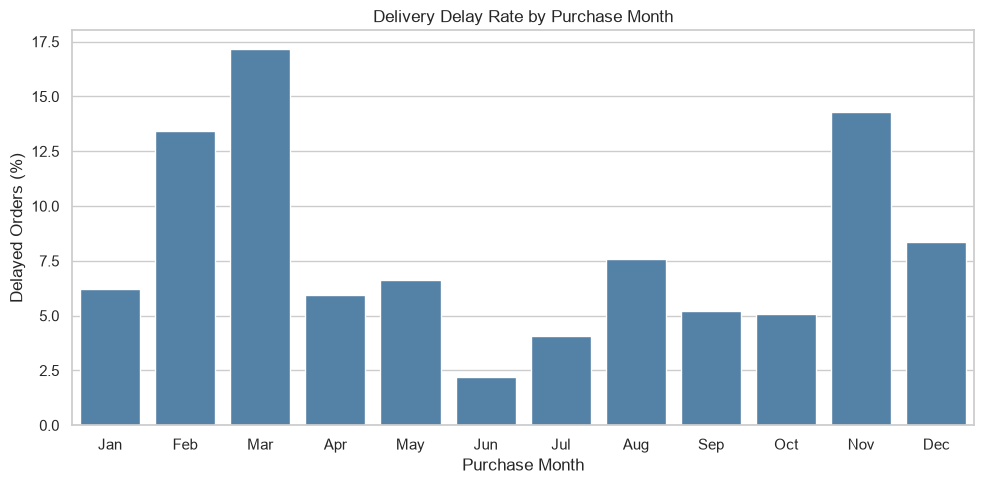

,purchase_month,delay_percentage
0,1,6.23
1,2,13.41
2,3,17.15
3,4,5.96
4,5,6.64
5,6,2.21
6,7,4.08
7,8,7.58
8,9,5.23
9,10,5.06


In [27]:
# Calculate delay rate by purchase month
monthly_delay = (
    final_df.groupby("purchase_month")["delivery_status"]
    .mean()
    .mul(100)
    .reset_index(name="delay_percentage")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_delay,
    x="purchase_month",
    y="delay_percentage",
    color="steelblue"
)

plt.title("Delivery Delay Rate by Purchase Month")
plt.xlabel("Purchase Month")
plt.ylabel("Delayed Orders (%)")
plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

display(monthly_delay.round(2))

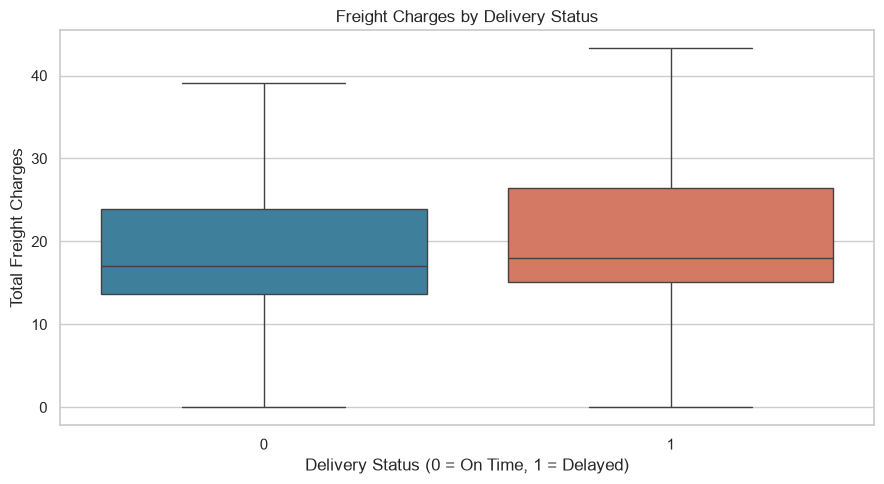

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=final_df,
    x="delivery_status",
    y="total_freight",
    hue="delivery_status",
    palette=["#2E86AB", "#E76F51"],
    legend=False,
    showfliers=False
)

plt.title("Freight Charges by Delivery Status")
plt.xlabel("Delivery Status (0 = On Time, 1 = Delayed)")
plt.ylabel("Total Freight Charges")

plt.tight_layout()
plt.show()

In [29]:
monthly_analysis = final_df.groupby("purchase_month").agg(
    total_orders=("delivery_status", "count"),
    delayed_orders=("delivery_status", "sum"),
    delay_rate=("delivery_status", "mean")
).reset_index()

monthly_analysis["delay_rate"] *= 100

display(monthly_analysis.round(2))

,purchase_month,total_orders,delayed_orders,delay_rate
0,1,7819,487,6.23
1,2,8208,1101,13.41
2,3,9549,1638,17.15
3,4,9101,542,5.96
4,5,10294,684,6.64
5,6,9231,204,2.21
6,7,10028,409,4.08
7,8,10544,799,7.58
8,9,4151,217,5.23
9,10,4743,240,5.06


In [30]:
weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_analysis = final_df.groupby("purchase_day_of_week").agg(
    total_orders=("delivery_status", "count"),
    delayed_orders=("delivery_status", "sum"),
    delay_rate=("delivery_status", "mean")
).reset_index()

weekday_analysis["day"] = weekday_analysis[
    "purchase_day_of_week"
].map(weekday_names)

weekday_analysis["delay_rate"] *= 100

display(weekday_analysis[[
    "day", "total_orders", "delayed_orders", "delay_rate"
]].round(2))

,day,total_orders,delayed_orders,delay_rate
0,Monday,15701,1421,9.05
1,Tuesday,15502,1316,8.49
2,Wednesday,15074,1176,7.80
3,Thursday,14322,1084,7.57
4,Friday,13684,1156,8.45
5,Saturday,10555,802,7.60
6,Sunday,11632,871,7.49


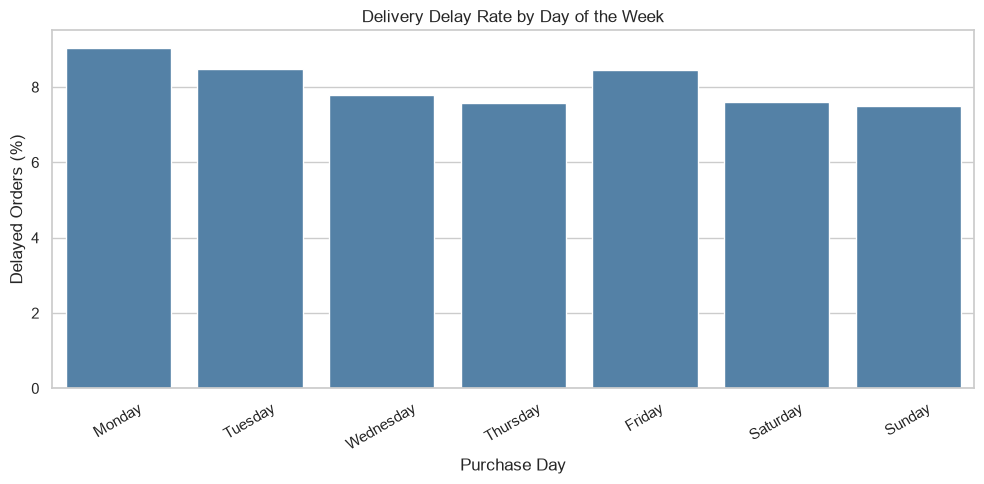

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_analysis,
    x="day",
    y="delay_rate",
    color="steelblue",
    order=[
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]
)

plt.title("Delivery Delay Rate by Day of the Week")
plt.xlabel("Purchase Day")
plt.ylabel("Delayed Orders (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 4.1 Categorical Attribute Analysis

In [32]:
# Calculate delivery delay rate by payment type

payment_analysis = (
    final_df.groupby("main_payment_type")
    .agg(
        total_orders=("delivery_status", "count"),
        delayed_orders=("delivery_status", "sum"),
        delay_rate=("delivery_status", "mean")
    )
    .reset_index()
)

payment_analysis["delay_rate"] = payment_analysis["delay_rate"] * 100

payment_analysis = payment_analysis.sort_values(
    by="delay_rate",
    ascending=False
)

display(payment_analysis)

,main_payment_type,total_orders,delayed_orders,delay_rate
3,unknown,1,1,100.000000
0,boleto,19191,1704,8.879162
2,debit_card,1483,118,7.956844
1,credit_card,73934,5871,7.940866
4,voucher,1861,132,7.092961


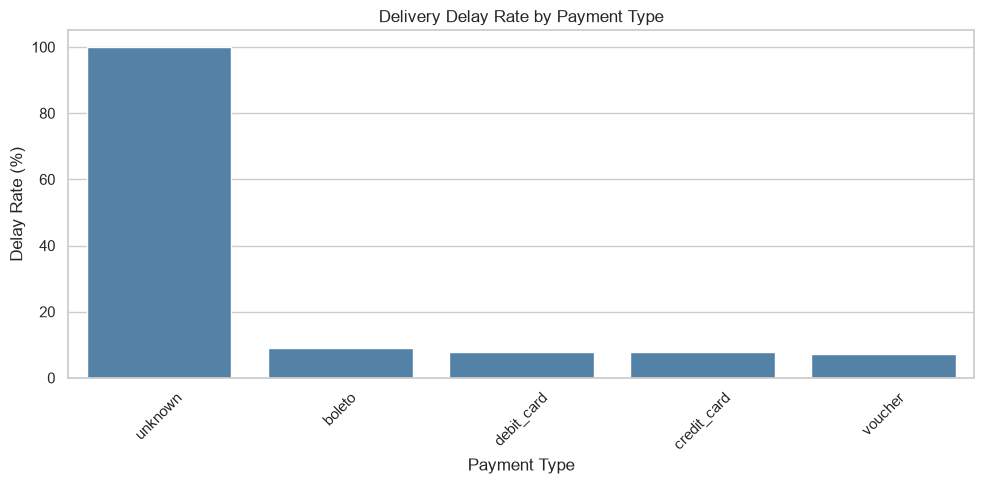

In [33]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_analysis,
    x="main_payment_type",
    y="delay_rate",
    color="steelblue"
)

plt.title("Delivery Delay Rate by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
# Calculate delivery delay rate by customer state

state_analysis = (
    final_df.groupby("customer_state")
    .agg(
        total_orders=("delivery_status", "count"),
        delayed_orders=("delivery_status", "sum"),
        delay_rate=("delivery_status", "mean")
    )
    .reset_index()
)

state_analysis["delay_rate"] = state_analysis["delay_rate"] * 100

# Focus on states with at least 100 orders
state_analysis = state_analysis[
    state_analysis["total_orders"] >= 100
]

state_analysis = state_analysis.sort_values(
    by="delay_rate",
    ascending=False
)

display(state_analysis)

,customer_state,total_orders,delayed_orders,delay_rate
1,AL,397,95,23.929471
9,MA,717,141,19.665272
16,PI,476,76,15.966387
5,CE,1279,196,15.324472
24,SE,335,51,15.223881
4,BA,3256,457,14.035627
18,RJ,12350,1664,13.473684
26,TO,274,35,12.773723
13,PA,946,117,12.367865
7,ES,1995,244,12.230576


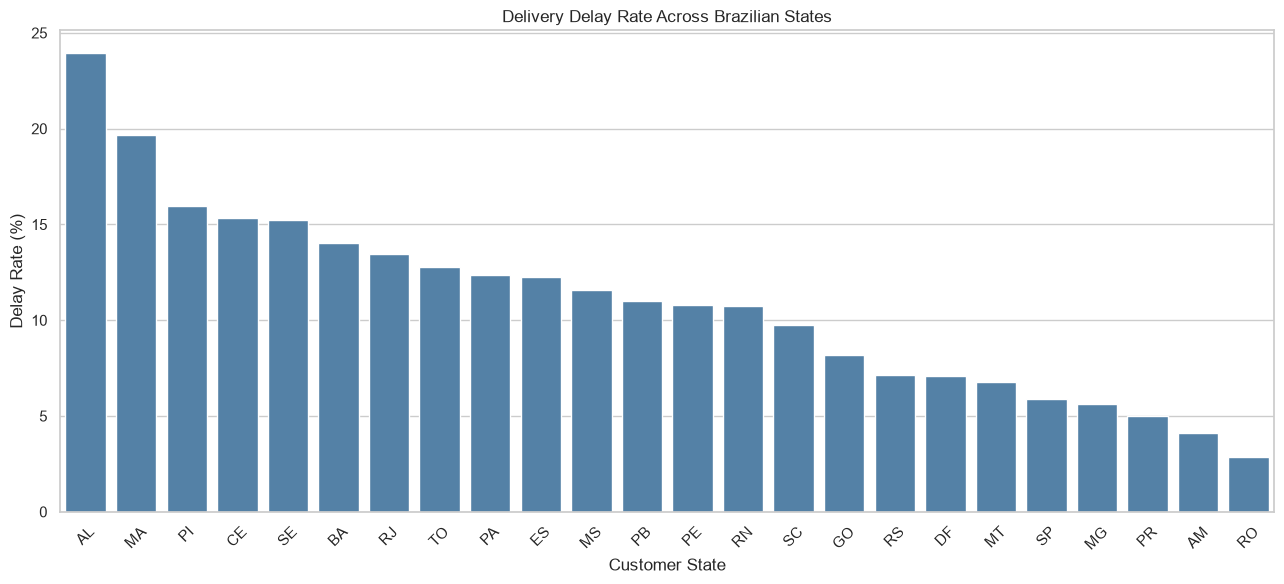

In [35]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=state_analysis,
    x="customer_state",
    y="delay_rate",
    color="steelblue"
)

plt.title("Delivery Delay Rate Across Brazilian States")
plt.xlabel("Customer State")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

The categorical analysis investigates whether delivery delay rates
differ across payment methods and customer states.

Payment methods may be associated with different purchasing patterns,
while customer location may reflect geographical differences in
delivery conditions.

However, differences in delay rates do not necessarily indicate
causation. The number of orders in each category must also be
considered when interpreting the results.

### 4.2 Correlation Analysis

Correlation analysis is used to investigate the relationships between
numerical attributes in the integrated dataset.

Pearson correlation is used to measure linear relationships between
numerical variables. The analysis also examines the relationship
between numerical attributes and the binary delivery_status target.

In [36]:
# Select meaningful numerical attributes

numerical_features = [
    "item_count",
    "total_price",
    "total_freight",
    "average_item_price",
    "unique_sellers",
    "total_payment",
    "max_installments",
    "purchase_month",
    "purchase_day",
    "purchase_day_of_week",
    "purchase_hour",
    "estimated_delivery_days",
    "delivery_status"
]

correlation_matrix = final_df[numerical_features].corr(method="pearson")

display(correlation_matrix.round(3))

,item_count,total_price,total_freight,average_item_price,unique_sellers,total_payment,max_installments,purchase_month,purchase_day,purchase_day_of_week,purchase_hour,estimated_delivery_days,delivery_status
item_count,1.000,0.153,0.439,-0.059,0.285,0.190,0.068,0.000,0.011,-0.011,-0.010,0.016,-0.016
total_price,0.153,1.000,0.411,0.933,0.043,0.996,0.314,0.002,-0.008,-0.003,0.005,0.076,0.016
total_freight,0.439,0.411,1.000,0.299,0.133,0.491,0.199,0.005,-0.009,-0.004,0.000,0.240,0.025
average_item_price,-0.059,0.933,0.299,1.000,-0.021,0.921,0.316,0.001,-0.010,-0.000,0.008,0.074,0.021
unique_sellers,0.285,0.043,0.133,-0.021,1.000,0.054,0.063,0.005,0.003,0.012,-0.004,0.024,-0.028
total_payment,0.190,0.996,0.491,0.921,0.054,1.000,0.320,0.002,-0.008,-0.003,0.004,0.097,0.017
max_installments,0.068,0.314,0.199,0.316,0.063,0.320,1.000,0.031,0.002,0.026,0.013,0.093,0.009
purchase_month,0.000,0.002,0.005,0.001,0.005,0.002,0.031,1.000,0.002,0.021,-0.004,-0.093,-0.025
purchase_day,0.011,-0.008,-0.009,-0.010,0.003,-0.008,0.002,0.002,1.000,-0.024,-0.012,-0.029,0.007
purchase_day_of_week,-0.011,-0.003,-0.004,-0.000,0.012,-0.003,0.026,0.021,-0.024,1.000,0.010,0.068,-0.015


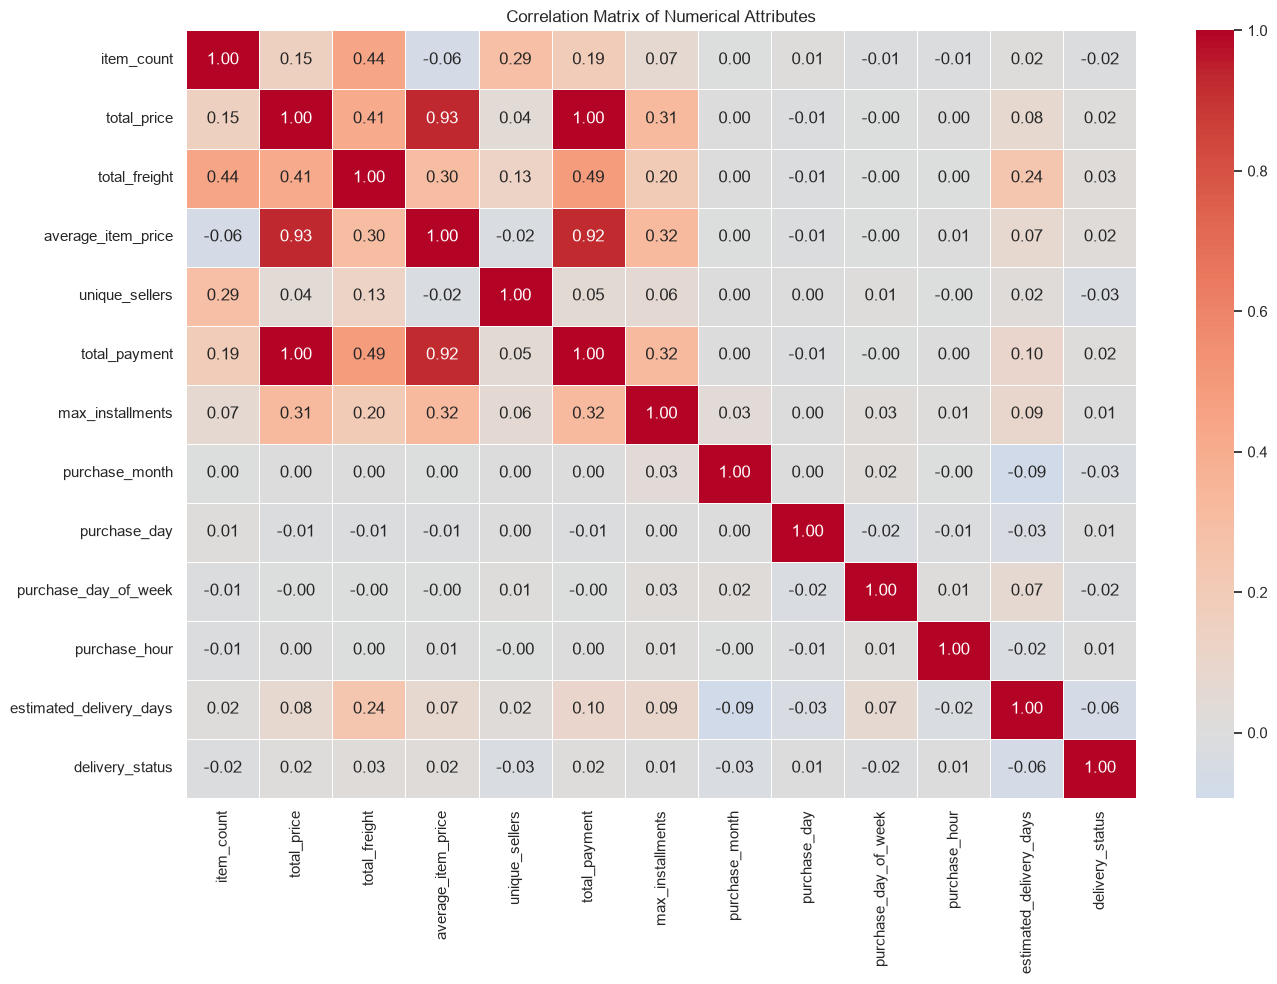

In [37]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Matrix of Numerical Attributes")
plt.tight_layout()
plt.show()

In [38]:
# Examine correlations with the target variable

target_correlation = (
    correlation_matrix["delivery_status"]
    .drop("delivery_status")
    .sort_values(ascending=False)
)

display(target_correlation.to_frame(name="Correlation with Delivery Status"))

,Correlation with Delivery Status
total_freight,0.025328
average_item_price,0.021348
total_payment,0.017483
total_price,0.015700
max_installments,0.008977
purchase_hour,0.008667
purchase_day,0.006776
purchase_day_of_week,-0.015293
item_count,-0.015850
purchase_month,-0.025390


### Interpretation

The correlation matrix helps identify relationships between numerical
attributes and delivery status.

Positive correlations indicate that higher values of an attribute
are associated with a higher delayed-order indicator, while negative
correlations indicate the opposite.

Correlation does not establish causation. Furthermore, weak linear
correlation does not necessarily mean that an attribute has no
predictive value.

### 4.3 Categorical Association Analysis

The Chi-Square Test of Independence is used to investigate whether
delivery status is statistically associated with categorical
attributes.

The null hypothesis (H0) states that delivery status and the selected
categorical attribute are independent.

The alternative hypothesis (H1) states that an association exists
between them.

In [39]:
from scipy.stats import chi2_contingency

# Select categorical attributes
categorical_features = [
    "main_payment_type",
    "customer_state"
]

chi_square_results = []

for feature in categorical_features:

    contingency_table = pd.crosstab(
        final_df[feature],
        final_df["delivery_status"]
    )

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    chi_square_results.append({
        "Attribute": feature,
        "Chi-Square Statistic": chi2,
        "Degrees of Freedom": dof,
        "P-Value": p_value,
        "Association": "Significant" if p_value < 0.05 else "Not Significant"
    })

chi_square_df = pd.DataFrame(chi_square_results)

display(chi_square_df)

,Attribute,Chi-Square Statistic,Degrees of Freedom,P-Value,Association
0,main_payment_type,32.024026,4,0.000002,Significant
1,customer_state,1623.190169,26,0.000000,Significant


In [40]:
# Calculate Cramer's V for categorical associations
import numpy as np
cramers_results = []

for feature in categorical_features:

    contingency_table = pd.crosstab(
        final_df[feature],
        final_df["delivery_status"]
    )

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    cramers_results.append({
        "Attribute": feature,
        "Cramer's V": cramers_v,
        "P-Value": p_value
    })

cramers_df = pd.DataFrame(cramers_results)

display(cramers_df)

,Attribute,Cramer's V,P-Value
0,main_payment_type,0.018220,0.000002
1,customer_state,0.129715,0.000000


### Interpretation

The Chi-Square Test investigates whether categorical attributes
are associated with delivery status.

Cramér's V measures the strength of the association.

A statistically significant p-value suggests evidence of an
association, but does not establish causation.

The strength of the association should also be considered,
especially when working with a large dataset.


### 4.4 Categorical Frequency and Mode Analysis

Frequency analysis examines how often each category occurs in the dataset. The mode identifies the most frequently occurring category.

This helps us understand the distribution of categorical attributes before interpreting their relationship with delivery delays.


In [41]:

# Select categorical attributes for frequency analysis
categorical_columns = [
    "main_payment_type",
    "customer_state",
    "customer_city"
]

for column in categorical_columns:

    print(f"\nFrequency distribution: {column}")

    frequency = final_df[column].value_counts(dropna=False)

    frequency_table = pd.DataFrame({
        "Frequency": frequency,
        "Percentage": (
            frequency / len(final_df) * 100
        ).round(2)
    })

    # Display the most common categories
    display(frequency_table.head(10))

    # Identify the mode
    print("Mode:", frequency.index[0])
    print("Mode frequency:", frequency.iloc[0])



Frequency distribution: main_payment_type


,Frequency,Percentage
main_payment_type,,
credit_card,73934,76.64
boleto,19191,19.89
voucher,1861,1.93
debit_card,1483,1.54
unknown,1,0.00


Mode: credit_card
Mode frequency: 73934

Frequency distribution: customer_state


,Frequency,Percentage
customer_state,,
SP,40494,41.98
RJ,12350,12.80
MG,11354,11.77
RS,5344,5.54
PR,4923,5.10
SC,3546,3.68
BA,3256,3.38
DF,2080,2.16
ES,1995,2.07


Mode: SP
Mode frequency: 40494

Frequency distribution: customer_city


,Frequency,Percentage
customer_city,,
sao paulo,15045,15.60
rio de janeiro,6601,6.84
belo horizonte,2697,2.80
brasilia,2071,2.15
curitiba,1489,1.54
campinas,1406,1.46
porto alegre,1341,1.39
salvador,1188,1.23
guarulhos,1143,1.18


Mode: sao paulo
Mode frequency: 15045



### Interpretation

The frequency analysis shows that credit card is the dominant payment method, representing 76.64% of all orders.

São Paulo (SP) is the most represented customer state, accounting for 41.98% of orders, while São Paulo city is the most frequent customer city, representing 15.60%.

These results indicate that the dataset has a strong geographical concentration. Therefore, regional delivery patterns should be interpreted while considering differences in the number of orders across states.

The unknown payment category contains only one record and is not sufficiently represented for meaningful interpretation.


In [42]:

# Select numerical attributes for skewness analysis
numerical_columns = [
    "item_count",
    "total_price",
    "total_freight",
    "average_item_price",
    "unique_sellers",
    "total_payment",
    "max_installments",
    "estimated_delivery_days"
]

# Calculate skewness
skewness_values = final_df[numerical_columns].skew()

skewness_table = pd.DataFrame({
    "Skewness": skewness_values
})

display(skewness_table.sort_values(
    by="Skewness",
    ascending=False
))


,Skewness
total_freight,12.276901
total_price,9.885400
unique_sellers,9.870271
total_payment,9.366702
average_item_price,7.869020
item_count,7.557602
max_installments,1.603681
estimated_delivery_days,0.905136


### Interpretation

The skewness analysis shows that all selected numerical attributes have positive skewness, indicating right-skewed distributions.

Total freight, total price, and total payment exhibit particularly high skewness. This suggests that most orders have relatively low values, while a small number of orders have substantially higher values.

Item count and unique sellers are also highly positively skewed, indicating that most orders contain relatively few items and sellers.

These results suggest the presence of extreme values in some numerical attributes. Therefore, further outlier investigation is necessary before final preprocessing and model development.

### 4.6 Outlier Analysis Using the IQR Method

The Interquartile Range (IQR) method is used to identify potential outliers in numerical attributes.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values outside these bounds are identified as potential outliers. However, they are not automatically removed because extreme values may represent genuine customer orders.

In [43]:
# Select numerical attributes for outlier analysis
numerical_columns = [
    "item_count",
    "total_price",
    "total_freight",
    "average_item_price",
    "unique_sellers",
    "total_payment",
    "max_installments",
    "estimated_delivery_days"
]

# Calculate potential outliers using the IQR method
outlier_results = []

for column in numerical_columns:

    Q1 = final_df[column].quantile(0.25)
    Q3 = final_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = final_df[
        (final_df[column] < lower_bound) |
        (final_df[column] > upper_bound)
    ]

    outlier_results.append({
        "Attribute": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(final_df) * 100, 2
        )
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table)

,Attribute,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,item_count,1.000000,1.000000,9635,9.99
1,total_price,-110.100000,305.900000,7658,7.94
2,total_freight,-1.405000,39.275000,9694,10.05
3,average_item_price,-105.100000,286.900000,7336,7.60
4,unique_sellers,1.000000,1.000000,1275,1.32
5,total_payment,-109.795000,348.005000,7575,7.85
6,max_installments,-3.500000,8.500000,6084,6.31
7,estimated_delivery_days,3.213069,43.524631,2427,2.52


### Interpretation

The IQR analysis identified potential outliers across several numerical attributes.

Total freight has the highest outlier percentage (10.05%), followed by item count (9.99%), total price (7.94%), total payment (7.85%), and average item price (7.60%).

Estimated delivery days has a relatively low outlier percentage of 2.52%.

The results indicate that some orders have unusually high values compared with the majority of transactions. However, these values may represent genuine customer orders rather than data errors.

Therefore, potential outliers will not be automatically removed. Removing valid high-value orders could result in losing useful information and reducing the representativeness of the dataset.

The IQR method also produced identical lower and upper bounds for item count and unique sellers because their distributions are highly concentrated around one.

### 4.7 Attribute Type Identification

Attributes are classified according to their data characteristics and role in the prediction task. This classification helps determine the appropriate preprocessing and feature-selection techniques.

In [44]:
# Display column names and their data types
attribute_types = pd.DataFrame({
    "Attribute": final_df.columns,
    "Data Type": final_df.dtypes.astype(str).values,
    "Unique Values": [
        final_df[column].nunique()
        for column in final_df.columns
    ]
})

display(attribute_types)

,Attribute,Data Type,Unique Values
0,order_id,str,96470
1,customer_id,str,96470
2,order_purchase_timestamp,datetime64[us],95948
3,order_estimated_delivery_date,datetime64[us],445
4,delivery_status,int64,2
5,customer_city,str,4085
6,customer_state,str,27
7,customer_zip_code_prefix,int64,14889
8,item_count,int64,17
9,total_price,float64,7634


### Interpretation

The dataset contains identifiers, date/time attributes, categorical attributes, discrete numerical attributes, continuous numerical attributes, and a binary target variable.

The delivery_status attribute is the target variable, representing whether an order was delivered on time or delayed.

The order_id and customer_id attributes are identifiers and will not be used as predictive features because they do not directly represent meaningful delivery characteristics.

The customer_zip_code_prefix attribute is stored numerically but represents a geographical location. Therefore, it should be treated as categorical rather than continuous numerical data.

The original timestamp attributes will be used to derive purchase-time features. The derived features include purchase year, month, day, day of the week, and hour.

The estimated_delivery_days attribute represents the difference between the estimated delivery date and the purchase timestamp. It is available at the time of purchase and can therefore be considered as a potential predictor.

All predictor attributes will undergo a feature availability and data leakage check before model development.

### 4.8 Investigating a Potential Confounding Variable

Customer geographical location may influence delivery outcomes because transportation distance, logistics infrastructure, and regional delivery conditions can vary across locations.

Customer state is therefore investigated as a potential confounding variable when examining relationships between order characteristics and delivery delays.

In [45]:
# Analyse delivery outcomes by customer state

state_analysis = final_df.groupby("customer_state").agg(
    Total_Orders=("delivery_status", "count"),
    Delayed_Orders=("delivery_status", "sum")
)

# Calculate delay percentage
state_analysis["Delay_Rate (%)"] = (
    state_analysis["Delayed_Orders"] /
    state_analysis["Total_Orders"] * 100
).round(2)

# Sort states by delay rate
state_analysis = state_analysis.sort_values(
    by="Delay_Rate (%)",
    ascending=False
)

display(state_analysis)

,Total_Orders,Delayed_Orders,Delay_Rate (%)
customer_state,,,
AL,397,95,23.93
MA,717,141,19.67
PI,476,76,15.97
CE,1279,196,15.32
SE,335,51,15.22
BA,3256,457,14.04
RJ,12350,1664,13.47
TO,274,35,12.77
PA,946,117,12.37


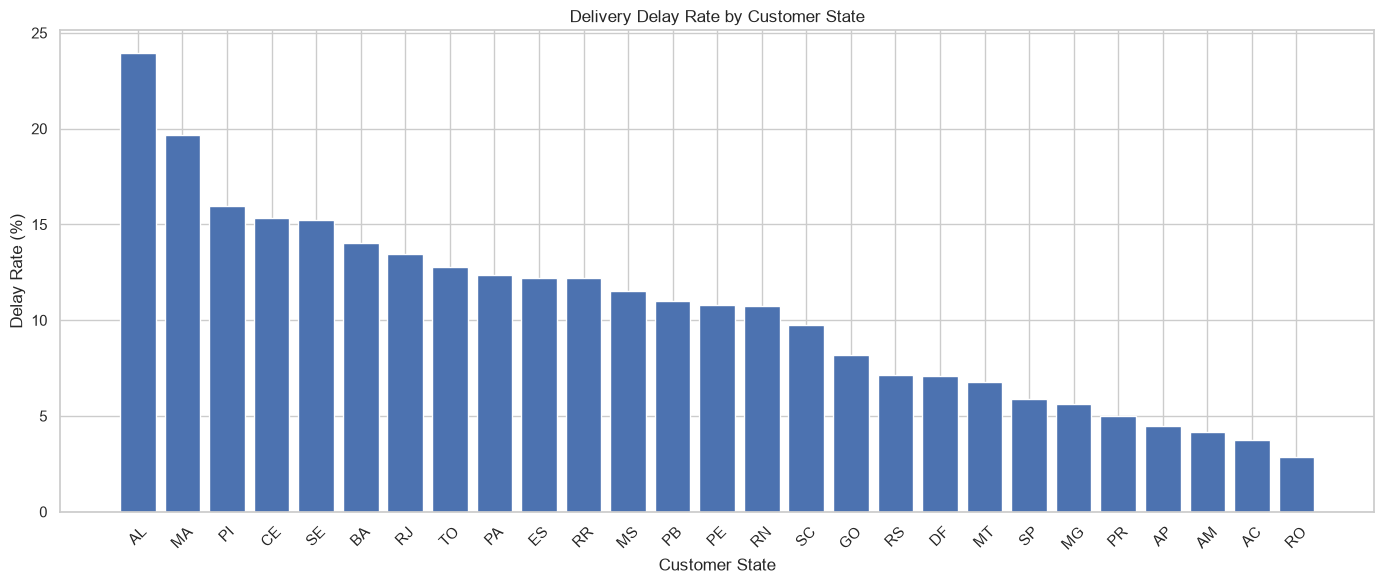

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    state_analysis.index,
    state_analysis["Delay_Rate (%)"]
)

plt.title("Delivery Delay Rate by Customer State")
plt.xlabel("Customer State")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Interpretation

The analysis reveals substantial variation in delivery delay rates across customer states.

Alagoas (AL) has the highest delay rate at 23.93%, followed by Maranhão (MA) at 19.67% and Piauí (PI) at 15.97%.

In contrast, Rondônia (RO) has the lowest delay rate at 2.88%, followed by Acre (AC) at 3.75%.

São Paulo (SP) contributes the largest number of orders (40,494), but its delay rate is relatively low at 5.89%. This demonstrates that states with more orders do not necessarily have higher delivery delay rates.

These differences suggest that geographical location may be associated with delivery outcomes. Factors such as transportation distance, logistics infrastructure, and regional delivery conditions could potentially influence these patterns.

Therefore, customer state is considered a plausible confounding variable when interpreting relationships between order characteristics and delivery delays. However, this analysis alone does not establish causation.

### 4.9 Mixed-attribute distance: Gower distance

Gower distance is appropriate for data containing numerical and categorical attributes. It calculates an attribute-level dissimilarity and averages the valid dissimilarities across attributes.

For a numerical attribute, dissimilarity is the absolute difference divided by the attribute range. For nominal categorical attributes, dissimilarity is 0 when values match and 1 when they differ. The overall distance is the mean of the attribute-level dissimilarities, excluding attributes missing for either record.

The next cell selects two actual records from `final_df`, displays their values and calculates the distance. This is an EDA demonstration only; Gower distance is not used as a model feature.

In [47]:
# Gower distance worked example using two actual orders.
gower_numeric = ["item_count", "total_price", "total_freight", "estimated_delivery_days"]
gower_categorical = ["customer_state", "main_payment_type"]
gower_columns = gower_numeric + gower_categorical

gower_sample = (
    final_df[gower_columns + ["order_id"]]
    .dropna(subset=gower_columns)
    .iloc[[0, 1]]
    .copy()
)
display(gower_sample.set_index("order_id"))

gower_components = {}
for col in gower_numeric:
    value_a, value_b = gower_sample[col].iloc[0], gower_sample[col].iloc[1]
    value_range = final_df[col].max() - final_df[col].min()
    gower_components[col] = abs(value_a - value_b) / value_range if value_range else 0.0

for col in gower_categorical:
    value_a, value_b = gower_sample[col].iloc[0], gower_sample[col].iloc[1]
    gower_components[col] = 0.0 if value_a == value_b else 1.0

gower_table = pd.DataFrame({
    "Attribute": list(gower_components.keys()),
    "Dissimilarity": list(gower_components.values())
})
gower_distance = gower_table["Dissimilarity"].mean()
display(gower_table.round(4))
print(f"Gower distance between the two selected real orders: {gower_distance:.4f}")
print("0 indicates identical values across selected attributes; 1 indicates maximum dissimilarity.")

,item_count,total_price,total_freight,estimated_delivery_days,customer_state,main_payment_type
order_id,,,,,,
e481f51cbdc54678b7cc49136f2d6af7,1,29.99,8.72,15.544063,SP,voucher
53cdb2fc8bc7dce0b6741e2150273451,1,118.70,22.76,19.137766,BA,boleto


,Attribute,Dissimilarity
0,item_count,0.0000
1,total_price,0.0066
2,total_freight,0.0078
3,estimated_delivery_days,0.0235
4,customer_state,1.0000
5,main_payment_type,1.0000


Gower distance between the two selected real orders: 0.3396
0 indicates identical values across selected attributes; 1 indicates maximum dissimilarity.


**Interpretation:** the table above shows each attribute’s contribution to the distance between the two displayed real orders. The overall Gower distance is the mean of the six dissimilarities. A value closer to 0 indicates greater similarity across the selected attributes; a value closer to 1 indicates greater dissimilarity. The result depends on the attributes selected.

### 4.10 EDA Summary

The exploratory data analysis examined the structure, quality, distribution, and relationships within the integrated Olist dataset.

The dataset contains 96,470 orders, with 88,644 on-time deliveries (91.89%) and 7,826 delayed deliveries (8.11%). This indicates a class imbalance that must be considered during model evaluation.

The analysis identified right-skewed numerical attributes and potential outliers. These values will be retained unless confirmed to be data errors.

Categorical analysis revealed differences in delay rates across payment methods and customer states. Geographical location was identified as a potential confounding variable.

Correlation and categorical association analyses provided additional insight into relationships between attributes and delivery status. However, statistical association does not establish causation.

The findings from EDA will guide feature selection, preprocessing, and model evaluation.

### 5. Feature Selection and Data Leakage Audit

Feature selection identifies attributes suitable for predicting delivery delays.

Only information available at the time of order placement should be included. Identifiers, the target variable, and attributes unavailable at the prediction point must be excluded.

The audit also considers redundant attributes and high-cardinality categorical variables.

**Prediction-time availability audit:** the intended prediction point is when the customer places the order. Actual delivery date and other post-purchase fields are used only to construct the historical target and must never be model inputs.

`estimated_delivery_days` is calculated from `order_purchase_timestamp` and `order_estimated_delivery_date`. It is retained only under the assumption that the estimated delivery date is known at purchase. The dataset table alone does not prove when the estimate was created or updated, so this assumption must be checked against the original dataset documentation or platform process. If the estimate was not available at purchase, remove this feature and rerun the model.

Payment-derived features are excluded because their availability at the exact prediction point has not been established. IDs and raw timestamps are excluded; timestamps are used only to derive purchase-time calendar attributes.

In [48]:
# Define the target variable
target = "delivery_status"

# Attributes excluded from prediction
excluded_features = [
    "order_id",
    "customer_id",
    "delivery_status",
    "order_purchase_timestamp",
    "order_estimated_delivery_date"
]

# Candidate numerical predictors
numerical_features = [
    "item_count",
    "total_price",
    "total_freight",
    "average_item_price",
    "unique_sellers",
    "total_payment",
    "max_installments",
    "payment_types",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "purchase_day_of_week",
    "purchase_hour",
    "estimated_delivery_days"
]

# Candidate categorical predictors
categorical_features = [
    "customer_city",
    "customer_state",
    "customer_zip_code_prefix",
    "main_payment_type"
]

# Create feature audit table
feature_audit = pd.DataFrame({
    "Feature": numerical_features + categorical_features,
    "Proposed Type": (
        ["Numerical"] * len(numerical_features)
        + ["Categorical"] * len(categorical_features)
    ),
    "Initial Decision": ["Review"] * (
        len(numerical_features) + len(categorical_features)
    )
})

display(feature_audit)

print("Excluded attributes:", excluded_features)
print("Target variable:", target)
print("Candidate numerical features:", len(numerical_features))
print("Candidate categorical features:", len(categorical_features))

,Feature,Proposed Type,Initial Decision
0,item_count,Numerical,Review
1,total_price,Numerical,Review
2,total_freight,Numerical,Review
3,average_item_price,Numerical,Review
4,unique_sellers,Numerical,Review
5,total_payment,Numerical,Review
6,max_installments,Numerical,Review
7,payment_types,Numerical,Review
8,purchase_year,Numerical,Review
9,purchase_month,Numerical,Review


Excluded attributes: ['order_id', 'customer_id', 'delivery_status', 'order_purchase_timestamp', 'order_estimated_delivery_date']
Target variable: delivery_status
Candidate numerical features: 14
Candidate categorical features: 4


In [49]:
availability_audit = pd.DataFrame([
    ["order_id / customer_id", "Identifier", "No", "Excluded"],
    ["order_purchase_timestamp", "Timestamp", "Yes, at purchase", "Used to derive calendar features"],
    ["order_estimated_delivery_date", "Estimated date", "Assumed yes; verify", "Only valid if known at purchase"],
    ["estimated_delivery_days", "Derived numeric", "Conditional", "Keep only if estimate was available at purchase"],
    ["order_delivered_customer_date", "Actual delivery timestamp", "No", "Post-purchase; target construction only"],
    ["delivery_status", "Target", "No", "Outcome label; never a predictor"],
    ["Payment-derived variables", "Payment information", "Not established", "Excluded from selected predictors"],
    ["customer_state", "Customer geography", "Yes, at order", "Selected categorical predictor"],
    ["Item/freight summaries", "Order contents/cost", "Verify process timing", "Assumed known at order placement"]
], columns=["Field/group", "Type", "Available at prediction time?", "Decision"])
display(availability_audit)

,Field/group,Type,Available at prediction time?,Decision
0,order_id / customer_id,Identifier,No,Excluded
1,order_purchase_timestamp,Timestamp,"Yes, at purchase",Used to derive calendar features
2,order_estimated_delivery_date,Estimated date,Assumed yes; verify,Only valid if known at purchase
3,estimated_delivery_days,Derived numeric,Conditional,Keep only if estimate was available at purchase
4,order_delivered_customer_date,Actual delivery timestamp,No,Post-purchase; target construction only
5,delivery_status,Target,No,Outcome label; never a predictor
6,Payment-derived variables,Payment information,Not established,Excluded from selected predictors
7,customer_state,Customer geography,"Yes, at order",Selected categorical predictor
8,Item/freight summaries,Order contents/cost,Verify process timing,Assumed known at order placement


In [50]:
# Final feature selection

target = "delivery_status"

selected_numerical_features = [
    "item_count",
    "total_price",
    "total_freight",
    "average_item_price",
    "unique_sellers",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "purchase_day_of_week",
    "purchase_hour",
    "estimated_delivery_days"
]

selected_categorical_features = [
    "customer_state"
]

# Features requiring further investigation
conditional_features = [
    "total_payment",
    "max_installments",
    "payment_types",
    "main_payment_type"
]

high_cardinality_features = [
    "customer_city",
    "customer_zip_code_prefix"
]

# Combine initial selected features
selected_features = (
    selected_numerical_features
    + selected_categorical_features
)

print("Selected numerical features:", len(selected_numerical_features))
print("Selected categorical features:", len(selected_categorical_features))
print("Total selected features:", len(selected_features))

print("\nConditional features:", conditional_features)
print("High-cardinality features:", high_cardinality_features)

print("\nExcluded identifiers and timestamps:")
print(excluded_features)

Selected numerical features: 11
Selected categorical features: 1
Total selected features: 12

Conditional features: ['total_payment', 'max_installments', 'payment_types', 'main_payment_type']
High-cardinality features: ['customer_city', 'customer_zip_code_prefix']

Excluded identifiers and timestamps:
['order_id', 'customer_id', 'delivery_status', 'order_purchase_timestamp', 'order_estimated_delivery_date']


## 5. Data Preprocessing

Data preprocessing prepares the selected attributes for machine learning. It includes data verification, train-test splitting, categorical encoding, and decisions regarding scaling and dimensionality reduction.

### 5.1 Selected Feature Verification

In [51]:
# Create the modelling dataset
X = final_df[selected_features].copy()
y = final_df[target].copy()

# Check dataset dimensions
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# Check data types
print("\nFeature data types:")
display(X.dtypes)

# Check missing values
print("\nMissing values:")
display(X.isnull().sum())

# Check target distribution
print("\nTarget distribution:")
display(y.value_counts())

print("\nTarget percentages:")
display((y.value_counts(normalize=True) * 100).round(2))

Feature matrix shape: (96470, 12)
Target shape: (96470,)

Feature data types:


item_count                   int64
total_price                float64
total_freight              float64
average_item_price         float64
unique_sellers               int64
purchase_year                int32
purchase_month               int32
purchase_day                 int32
purchase_day_of_week         int32
purchase_hour                int32
estimated_delivery_days    float64
customer_state                 str
dtype: object


Missing values:


item_count                 0
total_price                0
total_freight              0
average_item_price         0
unique_sellers             0
purchase_year              0
purchase_month             0
purchase_day               0
purchase_day_of_week       0
purchase_hour              0
estimated_delivery_days    0
customer_state             0
dtype: int64


Target distribution:


delivery_status
0    88644
1     7826
Name: count, dtype: int64


Target percentages:


delivery_status
0    91.89
1     8.11
Name: proportion, dtype: float64

### 5.2 Train-Test Split

The dataset is divided into training and testing subsets.

An 80:20 split is used, where 80% of the observations are used for model training and 20% are reserved for evaluating model performance.

Stratified sampling is applied to preserve the original class distribution in both subsets. This is important because delayed orders represent only 8.11% of the dataset.

A fixed random state of 27 is used to ensure reproducibility.

In [52]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=27,
    stratify=y
)

# Check dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (77176, 12)
Testing features: (19294, 12)

Training target distribution:
delivery_status
0    91.89
1     8.11
Name: proportion, dtype: float64

Testing target distribution:
delivery_status
0    91.89
1     8.11
Name: proportion, dtype: float64


### 5.3 Categorical Encoding

Categorical attributes must be converted into numerical representations before they can be used by the Decision Tree classifier.

One-Hot Encoding is applied to customer_state. This creates separate binary columns for the different customer states.

The encoder is fitted using the training data only and subsequently applied to the testing data to prevent data leakage.

In [53]:
from sklearn.preprocessing import OneHotEncoder

# Initialise encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit on training data and transform
X_train_encoded = encoder.fit_transform(
    X_train[selected_categorical_features]
)

# Transform testing data using the same encoder
X_test_encoded = encoder.transform(
    X_test[selected_categorical_features]
)

# Get encoded column names
encoded_columns = encoder.get_feature_names_out(
    selected_categorical_features
)

# Convert encoded arrays into DataFrames
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

print("Training encoded shape:", X_train_encoded_df.shape)
print("Testing encoded shape:", X_test_encoded_df.shape)

print("\nEncoded columns:")
print(list(encoded_columns))

display(X_train_encoded_df.head())

Training encoded shape: (77176, 27)
Testing encoded shape: (19294, 27)

Encoded columns:
['customer_state_AC', 'customer_state_AL', 'customer_state_AM', 'customer_state_AP', 'customer_state_BA', 'customer_state_CE', 'customer_state_DF', 'customer_state_ES', 'customer_state_GO', 'customer_state_MA', 'customer_state_MG', 'customer_state_MS', 'customer_state_MT', 'customer_state_PA', 'customer_state_PB', 'customer_state_PE', 'customer_state_PI', 'customer_state_PR', 'customer_state_RJ', 'customer_state_RN', 'customer_state_RO', 'customer_state_RR', 'customer_state_RS', 'customer_state_SC', 'customer_state_SE', 'customer_state_SP', 'customer_state_TO']


,customer_state_AC,customer_state_AL,customer_state_AM,customer_state_AP,customer_state_BA,customer_state_CE,customer_state_DF,customer_state_ES,customer_state_GO,customer_state_MA,...,customer_state_PR,customer_state_RJ,customer_state_RN,customer_state_RO,customer_state_RR,customer_state_RS,customer_state_SC,customer_state_SE,customer_state_SP,customer_state_TO
79024,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24282,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1970,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
34168,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
46282,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### 5.4 Combining Numerical and Encoded Features

After encoding the categorical attribute, the numerical and encoded features are combined to create the final modelling matrices.

The same feature structure is maintained for both training and testing datasets.

In [54]:
# Select numerical features
X_train_numerical = X_train[selected_numerical_features].copy()
X_test_numerical = X_test[selected_numerical_features].copy()

# Combine numerical and encoded categorical features
X_train_final = pd.concat(
    [X_train_numerical, X_train_encoded_df],
    axis=1
)

X_test_final = pd.concat(
    [X_test_numerical, X_test_encoded_df],
    axis=1
)

# Verify final modelling datasets
print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

print("\nMissing values in training:", X_train_final.isnull().sum().sum())
print("Missing values in testing:", X_test_final.isnull().sum().sum())

print("\nTraining and testing columns match:",
      list(X_train_final.columns) == list(X_test_final.columns))

Final training shape: (77176, 38)
Final testing shape: (19294, 38)

Missing values in training: 0
Missing values in testing: 0

Training and testing columns match: True


### 5.5 Normalization, PCA and Discretization

**Normalization**

Normalization is not applied because the selected algorithm is a Decision Tree Classifier. Decision Trees use feature-based splitting thresholds and are not sensitive to differences in numerical feature scales.

**Principal Component Analysis (PCA)**

PCA is not applied in the initial experiment because Decision Trees can handle the selected feature space directly. Additionally, PCA transforms original attributes into components, reducing the interpretability of the model.

**Discretization**

Discretization is not applied because Decision Trees can automatically identify suitable splitting thresholds for continuous numerical attributes.

Therefore, the original numerical values are retained for the initial Decision Tree model.

## 6. Decision Tree modelling and evaluation

### 6.1 Baseline classifier

A majority-class `DummyClassifier` is used as a baseline. It predicts the most frequent class for every order. Since the target is imbalanced, accuracy must be interpreted alongside delayed-class precision, recall and F1-score.

In [55]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create baseline classifier
baseline_model = DummyClassifier(strategy="most_frequent")

# Train baseline
baseline_model.fit(X_train_final, y_train)

# Predict test set
baseline_predictions = baseline_model.predict(X_test_final)

# Evaluate baseline
print("BASELINE MODEL RESULTS")

print("Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Precision:",
      precision_score(y_test, baseline_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, baseline_predictions, zero_division=0))

print("F1-score:",
      f1_score(y_test, baseline_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

BASELINE MODEL RESULTS
Accuracy: 0.9188867005286617
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion Matrix:
[[17729     0]
 [ 1565     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     17729
           1       0.00      0.00      0.00      1565

    accuracy                           0.92     19294
   macro avg       0.46      0.50      0.48     19294
weighted avg       0.84      0.92      0.88     19294



### Baseline Model Interpretation

The majority-class baseline achieved an accuracy of 91.89%, which reflects the proportion of on-time orders in the dataset.

However, the model predicted every order as on time and failed to identify any delayed orders.

The recall, precision, and F1-score for the delayed class were all zero.

The confusion matrix shows that all 1,565 delayed orders in the test set were incorrectly classified as on time.

Although the baseline achieves relatively high accuracy, it provides no practical value for identifying orders at risk of delivery delays.

Therefore, a more effective classification model is required. The Decision Tree classifier will be evaluated against this baseline, with particular attention given to the performance of the delayed class.

### 6.2 Decision Tree classifier

A Decision Tree classifier is used to predict whether an e-commerce order will be delivered on time or delayed.

The model recursively divides the dataset into subsets using feature-based decision rules.

Gini impurity is selected as the splitting criterion. Class weighting is also considered to give greater importance to the minority delayed class.

In [56]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Initialise Decision Tree
dt_model = DecisionTreeClassifier(
    criterion="gini",
    class_weight="balanced",
    random_state=27
)

# Train the model
dt_model.fit(X_train_final, y_train)

# Generate predictions
dt_predictions = dt_model.predict(X_test_final)

# Evaluate the model
print("DECISION TREE RESULTS")

print("Accuracy:",
      accuracy_score(y_test, dt_predictions))

print("Precision:",
      precision_score(y_test, dt_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, dt_predictions, zero_division=0))

print("F1-score:",
      f1_score(y_test, dt_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    zero_division=0
))

DECISION TREE RESULTS
Accuracy: 0.8722919042189282
Precision: 0.2116741500962155
Recall: 0.2108626198083067
F1-score: 0.2112676056338028

Confusion Matrix:
[[16500  1229]
 [ 1235   330]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93     17729
           1       0.21      0.21      0.21      1565

    accuracy                           0.87     19294
   macro avg       0.57      0.57      0.57     19294
weighted avg       0.87      0.87      0.87     19294



### Initial Decision Tree Results

The initial Decision Tree classifier achieved an accuracy of 87.23%, with a precision of 21.17%, recall of 21.09%, and F1-score of 21.13% for the delayed class.

Compared with the majority-class baseline, the Decision Tree achieved lower overall accuracy but successfully identified 330 delayed orders.

However, the model failed to identify 1,235 delayed orders, resulting in a relatively low recall.

The results demonstrate that class weighting alone was insufficient to achieve strong delayed-order prediction performance.

Further model tuning and evaluation are therefore necessary to improve the model's ability to identify delayed orders.

### 6.3 Overfitting analysis

Overfitting occurs when a model learns the training data too closely, including noise and specific patterns that do not generalize to unseen observations.

The training and testing performance are compared to investigate whether the Decision Tree is overfitting.

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict training and testing data
train_predictions = dt_model.predict(X_train_final)
test_predictions = dt_model.predict(X_test_final)

# Compare performance
overfitting_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, train_predictions),
        accuracy_score(y_test, test_predictions)
    ],
    "Precision": [
        precision_score(y_train, train_predictions, zero_division=0),
        precision_score(y_test, test_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_train, train_predictions, zero_division=0),
        recall_score(y_test, test_predictions, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_train, train_predictions, zero_division=0),
        f1_score(y_test, test_predictions, zero_division=0)
    ]
})

display(overfitting_results)

,Dataset,Accuracy,Precision,Recall,F1-score
0,Training,1.000000,1.000000,1.000000,1.000000
1,Testing,0.872292,0.211674,0.210863,0.211268


### Overfitting Analysis

The initial Decision Tree achieved perfect training performance, with accuracy, precision, recall, and F1-score of 100%.

However, its testing accuracy decreased to 87.23%, while the delayed-class F1-score decreased to 21.13%.

The substantial difference between training and testing performance indicates severe overfitting.

The unrestricted Decision Tree appears to have memorised patterns in the training dataset rather than learning patterns that generalise effectively to unseen observations.

To address this problem, tree complexity must be controlled through hyperparameter tuning, including maximum depth, minimum samples per split, and minimum samples per leaf.

### 6.4 Decision Tree complexity control

To reduce overfitting, different Decision Tree configurations are evaluated by restricting maximum depth and minimum samples per leaf.

These parameters control how complex the tree can become and prevent it from creating branches based on very small groups of observations.

The configurations are compared using accuracy, precision, recall, and F1-score, with particular attention to the delayed class.

In [58]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define tree configurations
tree_configs = {
    "Tree A": {"max_depth": 5, "min_samples_leaf": 20},
    "Tree B": {"max_depth": 10, "min_samples_leaf": 20},
    "Tree C": {"max_depth": 15, "min_samples_leaf": 50}
}

results = []

trained_trees = {}

for name, params in tree_configs.items():

    model = DecisionTreeClassifier(
        criterion="gini",
        class_weight="balanced",
        random_state=27,
        **params
    )

    model.fit(X_train_final, y_train)

    trained_trees[name] = model

    train_pred = model.predict(X_train_final)
    test_pred = model.predict(X_test_final)

    results.append({
        "Model": name,
        "Max Depth": params["max_depth"],
        "Min Samples Leaf": params["min_samples_leaf"],
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, test_pred, zero_division=0
        )
    })

complexity_results = pd.DataFrame(results)

display(complexity_results.round(4))

,Model,Max Depth,Min Samples Leaf,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1
0,Tree A,5,20,0.7315,0.7323,0.1781,0.6364,0.2783
1,Tree B,10,20,0.7437,0.7347,0.1867,0.6767,0.2927
2,Tree C,15,50,0.7386,0.7188,0.1758,0.6690,0.2785


### Interpretation of Decision Tree Complexity Experiments

Three Decision Tree configurations were evaluated using different maximum depths and minimum leaf sizes.

Tree A achieved a delayed-class recall of 63.64% and an F1-score of 27.83%.

Tree B achieved the best overall delayed-class performance, with precision of 18.67%, recall of 67.67%, and F1-score of 29.27%.

Tree C achieved a recall of 66.90% and an F1-score of 27.85%.

The training and testing accuracy differences were relatively small across the three configurations, suggesting improved generalization compared with the unrestricted Decision Tree.

Tree B was selected as the current candidate because it achieved the highest delayed-class F1-score and recall.

However, its relatively low precision indicates that further hyperparameter tuning is necessary.

### 6.5 Hyperparameter tuning using stratified cross-validation

Hyperparameter tuning is performed to identify a suitable Decision Tree configuration.

Stratified 5-fold cross-validation is used to preserve the class distribution across validation folds.

The F1-score for the delayed class is used as the primary optimization metric because identifying delayed orders is the main objective.

Hyperparameter tuning is performed using training data only. The testing dataset remains reserved for final model evaluation.

In [59]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint

# Base Decision Tree
dt_tuning = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=27
)

# Hyperparameter search space
param_distributions = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 8, 10, 12, 15, 20, None],
    "min_samples_split": randint(2, 51),
    "min_samples_leaf": randint(10, 101)
}

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=27
)

# Randomized search
random_search = RandomizedSearchCV(
    estimator=dt_tuning,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="f1",
    cv=cv,
    random_state=27,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
random_search.fit(X_train_final, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation F1-score:")
print(random_search.best_score_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters:
{'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 63, 'min_samples_split': 43}

Best cross-validation F1-score:
0.28242165766990207


### Hyperparameter Tuning Results

RandomizedSearchCV was used to identify suitable Decision Tree hyperparameters.

Stratified 5-fold cross-validation was applied using the delayed-class F1-score as the optimization metric.

The best configuration was:

- Criterion: Entropy
- Maximum depth: 8
- Minimum samples per leaf: 63
- Minimum samples to split: 43

The best mean cross-validation F1-score was 0.2824 (28.24%).

These parameters will be used to train the final candidate Decision Tree model, which will subsequently be evaluated on the untouched test dataset.

### 6.6 Training the tuned Decision Tree

In [60]:
# Retrieve the best model from RandomizedSearchCV
best_dt_model = random_search.best_estimator_

# Generate predictions
best_dt_predictions = best_dt_model.predict(X_test_final)

# Evaluate the tuned model
print("TUNED DECISION TREE RESULTS")

print("Accuracy:",
      accuracy_score(y_test, best_dt_predictions))

print("Precision:",
      precision_score(y_test, best_dt_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, best_dt_predictions, zero_division=0))

print("F1-score:",
      f1_score(y_test, best_dt_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, best_dt_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_dt_predictions,
    zero_division=0
))

TUNED DECISION TREE RESULTS
Accuracy: 0.7501814035451436
Precision: 0.19471018570624649
Recall: 0.663258785942492
F1-score: 0.30104408352668216

Confusion Matrix:
[[13436  4293]
 [  527  1038]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.76      0.85     17729
           1       0.19      0.66      0.30      1565

    accuracy                           0.75     19294
   macro avg       0.58      0.71      0.57     19294
weighted avg       0.90      0.75      0.80     19294



### Tuned Decision Tree Results

The tuned Decision Tree achieved an accuracy of 75.02%, precision of 19.47%, recall of 66.33%, and F1-score of 30.10% for the delayed class.

Compared with the initial Decision Tree, the tuned model substantially improved its ability to identify delayed orders.

The confusion matrix shows that the model correctly identified 1,038 delayed orders while missing 527 delayed orders.

However, it also incorrectly classified 4,293 on-time orders as delayed, resulting in relatively low precision.

The tuned model achieved the highest delayed-class F1-score among the evaluated configurations.

These findings demonstrate a trade-off between identifying more delayed orders and generating false alarms.

### 6.7 Classification threshold analysis

The default classification threshold of 0.5 is examined to determine whether alternative thresholds can improve the precision-recall balance.

Threshold selection is performed using training data only. The final selected threshold is subsequently evaluated on the independent test dataset.

In [61]:
# Obtain predicted probabilities for the positive class
train_probabilities = best_dt_model.predict_proba(X_train_final)[:, 1]

print("Minimum probability:", train_probabilities.min())
print("Maximum probability:", train_probabilities.max())

print("\nFirst 10 probabilities:")
print(train_probabilities[:10])

Minimum probability: 0.0
Maximum probability: 0.9594120278258571

First 10 probabilities:
[0.38216831 0.28086928 0.16305793 0.2768231  0.84308336 0.37066395
 0.16305793 0.69920544 0.29121345 0.70712691]


In [62]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

# Create stratified cross-validation
threshold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=27
)

# Generate out-of-fold probabilities
oof_probabilities = cross_val_predict(
    best_dt_model,
    X_train_final,
    y_train,
    cv=threshold_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall at different thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

# Calculate F1-score for each threshold
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

# Identify threshold with highest F1-score
best_index = np.argmax(f1_values)

best_threshold = thresholds[best_index]
best_cv_f1 = f1_values[best_index]

print("Best classification threshold:", round(best_threshold, 4))
print("Best cross-validation F1-score:", round(best_cv_f1, 4))
print("Precision at best threshold:", round(precision_values[best_index], 4))
print("Recall at best threshold:", round(recall_values[best_index], 4))

Best classification threshold: 0.6937
Best cross-validation F1-score: 0.3219
Precision at best threshold: 0.2487
Recall at best threshold: 0.456


In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Get predicted probabilities on the test set
test_probabilities = best_dt_model.predict_proba(
    X_test_final
)[:, 1]

# Default threshold predictions
default_predictions = (
    test_probabilities >= 0.5
).astype(int)

# Selected threshold predictions
threshold_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Compare both thresholds
threshold_results = []

for name, predictions in [
    ("Default (0.5)", default_predictions),
    ("Selected (0.6937)", threshold_predictions)
]:
    threshold_results.append({
        "Threshold": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(4))

print("\nConfusion Matrix - Selected Threshold:")
print(confusion_matrix(y_test, threshold_predictions))

print("\nClassification Report - Selected Threshold:")
print(classification_report(
    y_test,
    threshold_predictions,
    zero_division=0
))

,Threshold,Accuracy,Precision,Recall,F1-score
0,Default (0.5),0.7502,0.1947,0.6633,0.3010
1,Selected (0.6937),0.8371,0.2534,0.5182,0.3404



Confusion Matrix - Selected Threshold:
[[15340  2389]
 [  754   811]]

Classification Report - Selected Threshold:
              precision    recall  f1-score   support

           0       0.95      0.87      0.91     17729
           1       0.25      0.52      0.34      1565

    accuracy                           0.84     19294
   macro avg       0.60      0.69      0.62     19294
weighted avg       0.90      0.84      0.86     19294



### Classification Threshold Evaluation

The default classification threshold of 0.5 was compared with the cross-validation-selected threshold of 0.6937.

At the default threshold, the model achieved an accuracy of 75.02%, precision of 19.47%, recall of 66.33%, and F1-score of 30.10% for the delayed class.

At the selected threshold of 0.6937, accuracy increased to 83.71%, precision increased to 25.34%, and F1-score increased to 34.04%. However, recall decreased to 51.82%.

The confusion matrix shows that the selected threshold correctly identified 811 delayed orders and missed 754 delayed orders.

The number of false positives decreased from 4,293 to 2,389.

Therefore, the selected threshold provides a better precision-recall balance according to the F1-score, although it identifies fewer delayed orders.

The threshold of 0.6937 was selected using out-of-fold predictions from the training data, while the reported final performance was measured on the independent test dataset.

### 6.8 ROC curve and AUC evaluation

ROC-AUC: 0.7602


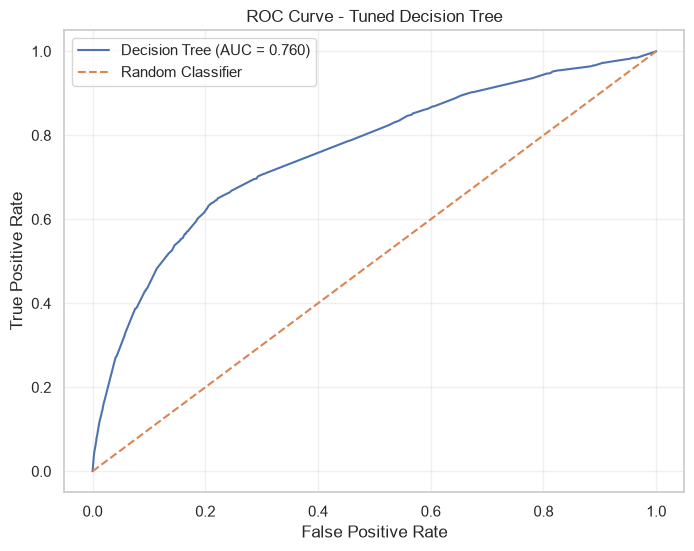

In [64]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Calculate ROC curve using test probabilities
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

print("ROC-AUC:", round(roc_auc, 4))

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Decision Tree")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### ROC Curve and ROC-AUC Interpretation

The tuned Decision Tree achieved a ROC-AUC score of **0.7602** on the test dataset. This indicates that the model has a reasonably good ability to distinguish between delayed and on-time orders across different classification thresholds.

The ROC-AUC score is above 0.5, which represents random classification, showing that the model has learned meaningful patterns from the dataset. However, the model does not achieve perfect discrimination, indicating that some delayed and on-time orders remain difficult to distinguish.

ROC-AUC evaluates the model's ranking ability independently of a specific classification threshold. Therefore, it complements precision, recall, and F1-score, which evaluate predictions at a chosen threshold.

Average Precision (PR-AUC): 0.2673


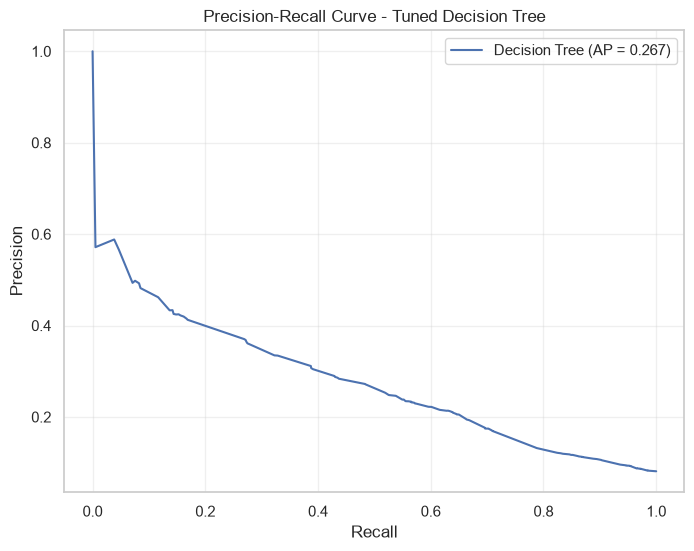

In [65]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test, test_probabilities
)

average_precision = average_precision_score(y_test, test_probabilities)

print("Average Precision (PR-AUC):", round(average_precision, 4))

plt.figure(figsize=(8, 6))
plt.plot(
    recall_values,
    precision_values,
    label=f"Decision Tree (AP = {average_precision:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Tuned Decision Tree")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Precision-Recall Curve and Average Precision Interpretation

The tuned Decision Tree achieved an Average Precision (AP) score of **0.2673** on the test dataset.

Since the dataset is imbalanced, with delayed orders representing only 8.11% of observations, the Precision-Recall curve provides useful insight into the model's ability to identify the minority class.

The obtained AP score is higher than the positive-class prevalence of 0.0811, indicating that the model performs better than random ranking when identifying delayed orders.

However, the score also indicates that the model's ability to identify delayed orders while maintaining high precision remains limited. Therefore, further improvements may be needed before the model can be considered reliable for practical deployment.

                    Feature  Importance
6            purchase_month    0.341760
10  estimated_delivery_days    0.212523
36        customer_state_SP    0.094668
5             purchase_year    0.067057
2             total_freight    0.062068
7              purchase_day    0.060812
29        customer_state_RJ    0.054051
21        customer_state_MG    0.033311
3        average_item_price    0.016660
15        customer_state_BA    0.015877
1               total_price    0.012875
9             purchase_hour    0.009442
16        customer_state_CE    0.007936
8      purchase_day_of_week    0.004816
34        customer_state_SC    0.002955


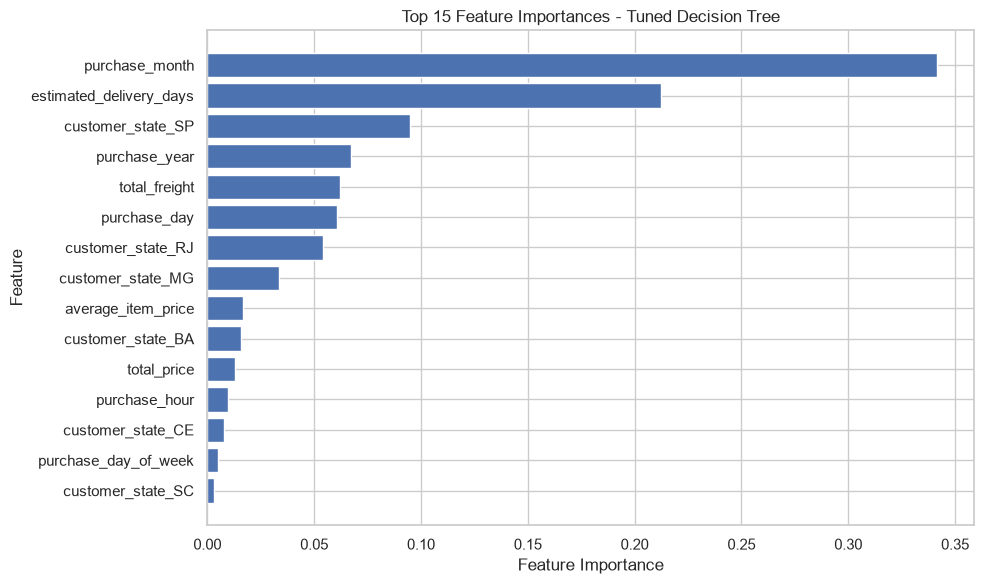

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": best_dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance.head(15)["Feature"][::-1],
    feature_importance.head(15)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Tuned Decision Tree")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

Feature importance was extracted from the tuned Decision Tree to identify the variables that contributed most to its predictions.

The results show that **purchase_month** was the most influential feature, with an importance score of 0.3418 (34.18%). This suggests that seasonal patterns play an important role in predicting delivery delays.

The second most important feature was **estimated_delivery_days**, with an importance score of 0.2125 (21.25%). This indicates that the estimated delivery window provides useful information for distinguishing delayed from on-time orders.

Geographical features also contributed to the model, particularly customer_state_SP (9.47%), customer_state_RJ (5.41%), and customer_state_MG (3.33%). Other relevant variables included purchase_year, total_freight, and purchase_day.

Overall, the model relies primarily on temporal and geographical information, together with the estimated delivery window and freight cost.

Feature importance represents the relative contribution of features to the tree's impurity reduction. It does not establish causation, and importance can be distributed among correlated features.

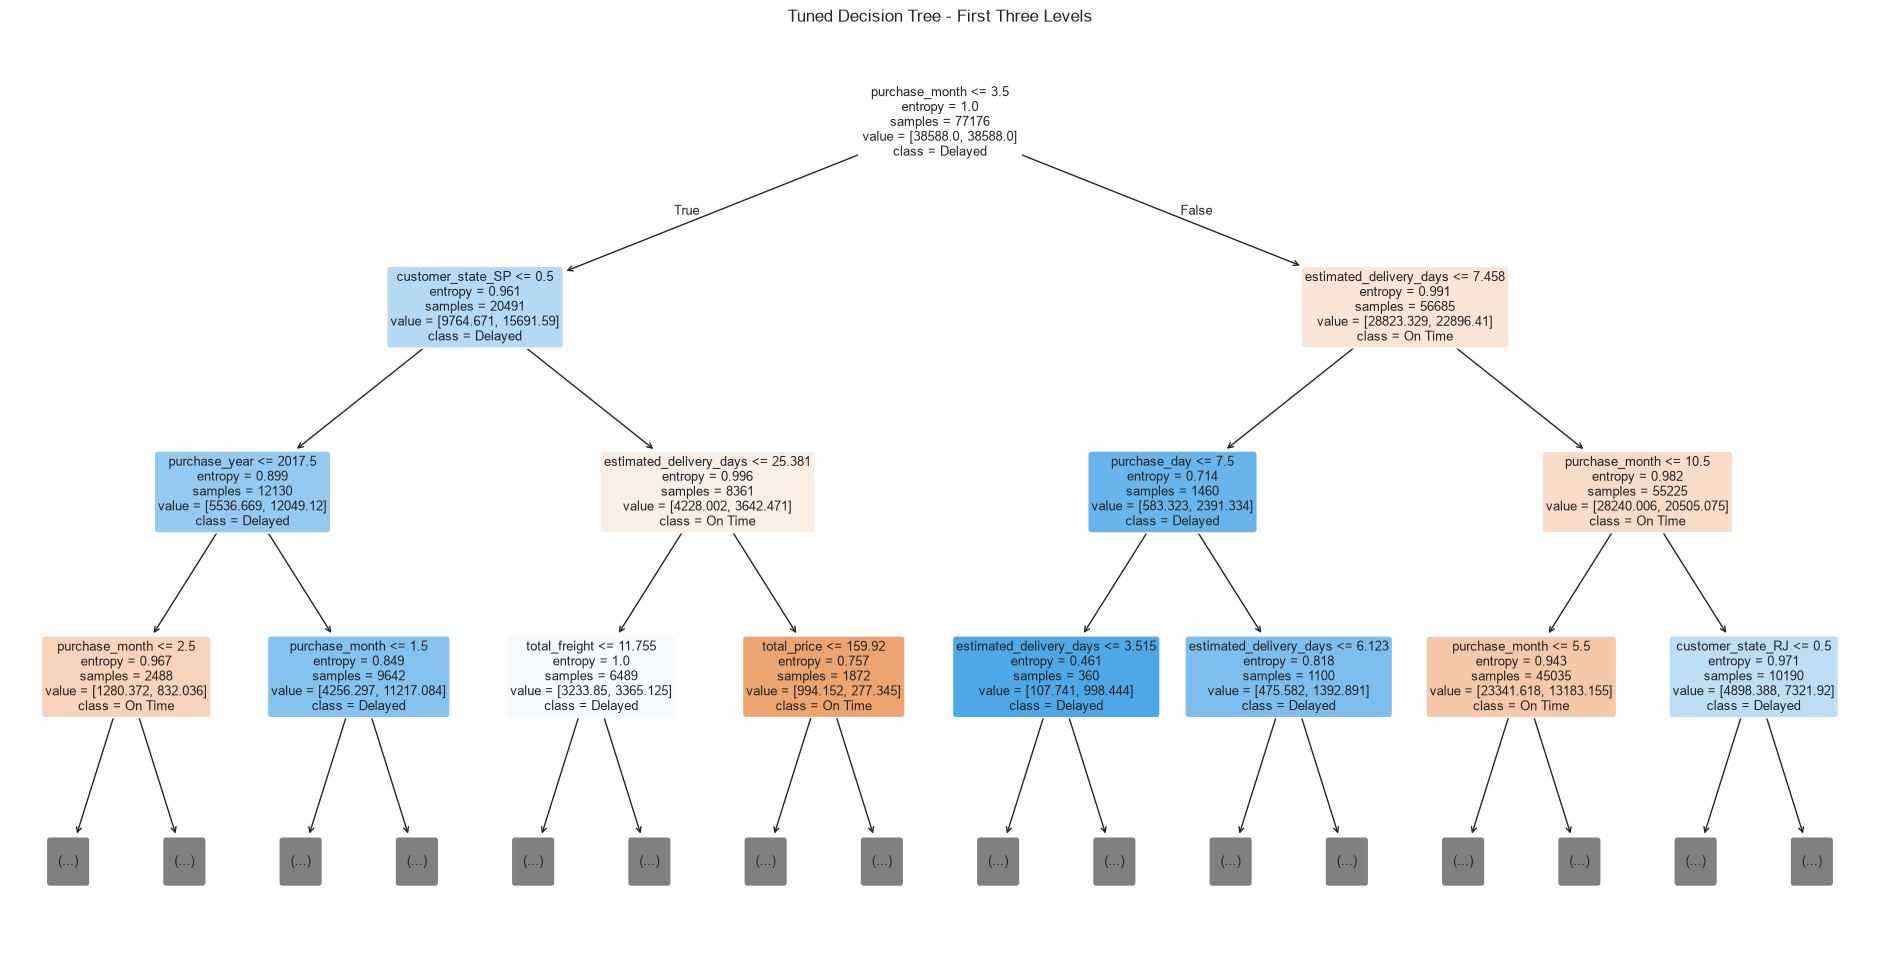

In [67]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    best_dt_model,
    feature_names=X_train_final.columns,
    class_names=["On Time", "Delayed"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Tuned Decision Tree - First Three Levels")
plt.show()

### Decision Tree Visualization and Interpretation

The first three levels of the tuned Decision Tree were visualized to understand how the model makes predictions.

The root node splits the data using **purchase_month <= 3.5**, separating orders purchased between January and March from those purchased between April and December. This confirms that purchase month is the most influential feature identified during the feature importance analysis.

For orders purchased between January and March, the model considers customer location, particularly whether the customer is in São Paulo. Further splits involve purchase year and estimated delivery days.

For orders purchased between April and December, the model first considers estimated_delivery_days <= 7.458. Subsequent splits involve purchase day, purchase month, and customer location.

The visualization demonstrates that the model combines temporal, geographical, and order-related characteristics to classify delivery outcomes.

The displayed tree is limited to the first three levels for readability; the complete model contains additional decision levels. Since class_weight='balanced' was used, the class values displayed in the nodes represent weighted observations rather than raw class counts.

In [68]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, threshold_predictions)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 15340
False Positives: 2389
False Negatives: 754
True Positives: 811


### Confusion Matrix and Error Analysis

The confusion matrix was used to examine the prediction errors made by the tuned Decision Tree at the selected classification threshold of 0.6937.

The model correctly classified 15,340 on-time orders (True Negatives) and 811 delayed orders (True Positives).

However, it incorrectly classified 2,389 on-time orders as delayed (False Positives). These predictions could result in unnecessary customer notifications and additional operational workload.

The model also failed to identify 754 genuinely delayed orders (False Negatives). These missed cases are particularly important because the company would lose opportunities to notify customers or take preventive action.

Overall, the model identified 51.82% of actual delayed orders, with a precision of 25.34%. This demonstrates that the model can identify a meaningful proportion of delayed orders, but its false-positive rate remains a limitation.

From a business perspective, the company must consider the cost of unnecessary alerts against the cost of failing to identify genuinely delayed deliveries.

In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate additional metrics
specificity = tn / (tn + fp)
false_positive_rate = fp / (fp + tn)
false_negative_rate = fn / (fn + tp)

print("Specificity:", round(specificity, 4))
print("False Positive Rate:", round(false_positive_rate, 4))
print("False Negative Rate:", round(false_negative_rate, 4))

Specificity: 0.8652
False Positive Rate: 0.1348
False Negative Rate: 0.4818


### Specificity and Error Rate Analysis

The tuned Decision Tree achieved a specificity of **86.52%**, indicating that it correctly identifies most orders that are delivered on time.

The False Positive Rate was **13.48%**, meaning that 13.48% of genuinely on-time orders were incorrectly classified as delayed.

The False Negative Rate was **48.18%**, indicating that the model failed to identify approximately half of the genuinely delayed orders.

These results demonstrate that the model is better at recognizing on-time deliveries than delayed deliveries. Although the selected threshold improves the balance between precision and recall, identifying delayed orders remains a major challenge.

From a business perspective, further improvements should focus on reducing false negatives while maintaining an acceptable number of false positives.

In [70]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Baseline": [0.9189, 0.0000, 0.0000, 0.0000],
    "Tuned Decision Tree": [0.8371, 0.2534, 0.5182, 0.3404]
})

print(comparison.to_string(index=False))

   Metric  Baseline  Tuned Decision Tree
 Accuracy    0.9189               0.8371
Precision    0.0000               0.2534
   Recall    0.0000               0.5182
 F1-score    0.0000               0.3404


### Baseline and Tuned Decision Tree Comparison

The baseline model achieved an accuracy of 91.89%, which initially appears higher than the tuned Decision Tree's accuracy of 83.71%.

However, the baseline uses a majority-class prediction strategy and classifies every order as on time. Consequently, it achieves zero precision, zero recall, and zero F1-score for the delayed class.

In contrast, the tuned Decision Tree identifies delayed orders with a precision of 25.34%, recall of 51.82%, and F1-score of 34.04%.

Although the Decision Tree has lower overall accuracy, it is more useful for the project's objective of identifying potentially delayed orders.

This comparison demonstrates why accuracy alone is misleading when evaluating classification models on imbalanced datasets. Metrics such as precision, recall, and F1-score provide a more meaningful assessment of minority-class performance.

Therefore, the tuned Decision Tree is selected as the more appropriate model for this prediction task.

## 6.9 Additional experiment: Random Forest Classifier

### Motivation

The Decision Tree is the primary classification technique required by the project brief. However, a single tree can be sensitive to changes in the training data and may overfit. To investigate whether an ensemble approach can improve delayed-order prediction, an additional Random Forest experiment is conducted.

Random Forest is an ensemble learning method that trains multiple Decision Trees using bootstrap samples and randomized feature subsets. The trees' predictions are combined to produce the final classification. This can reduce the variance of an individual tree and may improve generalization, although an improvement is not guaranteed.

### Objective

The objective is to compare an ensemble of trees with the single Decision Tree using the same training data, test data and selected predictors. The comparison focuses on the minority class (`Delayed`), because delayed orders represent only 8.11% of the eligible dataset.

### Initial model configuration

The initial Random Forest uses 300 trees, a maximum depth of 12, a minimum of 20 samples to split an internal node, and at least 10 samples per leaf. The `sqrt` feature-selection setting introduces randomness at each split. `class_weight='balanced_subsample'` adjusts class weights within each bootstrap sample to address class imbalance. The random state is fixed at 27 for reproducibility.

These settings are an initial experiment rather than the result of an exhaustive hyperparameter search. The model is evaluated first at the default probability threshold of 0.5. A separate threshold-selection experiment below uses out-of-fold predictions from the training data only.


In [71]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=27,
    n_jobs=-1
)

# Train
rf_model.fit(X_train_final, y_train)

# Predict
rf_predictions = rf_model.predict(X_test_final)
rf_probabilities = rf_model.predict_proba(X_test_final)[:, 1]

# Evaluate
print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions))
print("Recall:", recall_score(y_test, rf_predictions))
print("F1 Score:", f1_score(y_test, rf_predictions))
print("ROC-AUC:", roc_auc_score(y_test, rf_probabilities))
print("Average Precision:", average_precision_score(y_test, rf_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.8213434228257489
Precision: 0.24960085151676423
Recall: 0.5993610223642173
F1 Score: 0.3524328386248356
ROC-AUC: 0.7942602659817843
Average Precision: 0.3073526979600489

Confusion Matrix:
[[14909  2820]
 [  627   938]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.84      0.90     17729
           1       0.25      0.60      0.35      1565

    accuracy                           0.82     19294
   macro avg       0.60      0.72      0.62     19294
weighted avg       0.90      0.82      0.85     19294



### Random Forest results at the default threshold

The initial Random Forest experiment achieved the following test-set results at the default classification threshold of 0.5:

| Metric | Result |
|---|---:|
| Accuracy | 82.13% |
| Delayed-class precision | 24.96% |
| Delayed-class recall | 59.94% |
| Delayed-class F1-score | 35.24% |
| ROC-AUC | 0.7943 |
| Average Precision | 0.3074 |

The confusion matrix was:

| | Predicted On Time | Predicted Delayed |
|---|---:|---:|
| Actual On Time | 14,909 | 2,820 |
| Actual Delayed | 627 | 938 |

The model correctly identified 938 of the 1,565 delayed orders and missed 627. It also generated 2,820 false-positive alerts for orders that were actually delivered on time.

The results show that the Random Forest identifies a larger proportion of delayed orders than the tuned Decision Tree at its selected threshold of 0.6937. However, that is not a fully controlled threshold comparison. The Random Forest is therefore also compared with the Decision Tree at a common threshold of 0.5, and its own threshold is selected using training-set cross-validation in the next experiment.


### 6.10 Random Forest threshold selection using training data

The default threshold of 0.5 is not necessarily the best threshold for identifying delayed orders. To investigate the precision-recall trade-off, a classification threshold is selected using out-of-fold predicted probabilities generated from the training set.

Five-fold stratified cross-validation is used. Each training observation receives a probability from a model that was not fitted on that observation. The threshold that maximizes the delayed-class F1-score on these out-of-fold predictions is selected. The test set is not used to choose the threshold.

After selecting the threshold, the Random Forest is refitted on the complete training set (as it already is above) and evaluated once on the held-out test set. This provides a second Random Forest evaluation at a training-selected threshold.


In [72]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

rf_threshold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=27
)

# Out-of-fold probabilities: every training row is predicted by a model
# that did not train on that row.
rf_oof_probabilities = cross_val_predict(
    rf_model,
    X_train_final,
    y_train,
    cv=rf_threshold_cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

rf_precision_values, rf_recall_values, rf_thresholds = precision_recall_curve(
    y_train,
    rf_oof_probabilities
)

rf_f1_values = (
    2 * rf_precision_values[:-1] * rf_recall_values[:-1]
    / (rf_precision_values[:-1] + rf_recall_values[:-1] + 1e-10)
)

rf_best_index = np.argmax(rf_f1_values)
rf_best_threshold = rf_thresholds[rf_best_index]

print("Random Forest threshold selected from training OOF predictions:",
      round(float(rf_best_threshold), 4))
print("Training OOF precision at selected threshold:",
      round(float(rf_precision_values[rf_best_index]), 4))
print("Training OOF recall at selected threshold:",
      round(float(rf_recall_values[rf_best_index]), 4))
print("Training OOF F1-score at selected threshold:",
      round(float(rf_f1_values[rf_best_index]), 4))


Random Forest threshold selected from training OOF predictions: 0.5863
Training OOF precision at selected threshold: 0.3044
Training OOF recall at selected threshold: 0.4034
Training OOF F1-score at selected threshold: 0.347


In [73]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score
)

# Evaluate the training-selected threshold on the held-out test set.
rf_threshold_predictions = (
    rf_probabilities >= rf_best_threshold
).astype(int)

print("RANDOM FOREST - TRAINING-SELECTED THRESHOLD")
print("-------------------------------------------")
print("Threshold:", round(float(rf_best_threshold), 4))
print("Accuracy:", accuracy_score(y_test, rf_threshold_predictions))
print("Precision:", precision_score(y_test, rf_threshold_predictions, zero_division=0))
print("Recall:", recall_score(y_test, rf_threshold_predictions, zero_division=0))
print("F1-score:", f1_score(y_test, rf_threshold_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, rf_probabilities))
print("Average Precision:", average_precision_score(y_test, rf_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_threshold_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_threshold_predictions, zero_division=0))


RANDOM FOREST - TRAINING-SELECTED THRESHOLD
-------------------------------------------
Threshold: 0.5863
Accuracy: 0.8780968176635223
Precision: 0.32040164308534913
Recall: 0.4485623003194888
F1-score: 0.3738019169329074
ROC-AUC: 0.7942602659817843
Average Precision: 0.3073526979600489

Confusion Matrix:
[[16240  1489]
 [  863   702]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.92      0.93     17729
           1       0.32      0.45      0.37      1565

    accuracy                           0.88     19294
   macro avg       0.63      0.68      0.65     19294
weighted avg       0.90      0.88      0.89     19294



### 6.11 Overall model comparison

The table below compares the majority-class baseline, the initial Decision Tree, the Decision Tree at the default threshold, the Decision Tree at its training-selected threshold, and Random Forest at both the default and training-selected thresholds.

Comparing the two models at the same default threshold of 0.5 provides a more controlled threshold comparison. The threshold-selected rows show the performance after selecting a threshold independently for each model using out-of-fold predictions from training data only.

The ROC-AUC and Average Precision scores do not depend on the classification threshold, so they are useful for comparing probability ranking performance. Accuracy, precision, recall and F1-score do depend on the threshold.


In [74]:
# Assemble a comparison using the saved Decision Tree and Random Forest results.
# ROC-AUC and Average Precision are threshold-independent.
comparison_rows = [
    {
        "Model / threshold": "Dummy baseline",
        "Accuracy": 0.9189,
        "Precision (Delayed)": 0.0000,
        "Recall (Delayed)": 0.0000,
        "F1 (Delayed)": 0.0000,
        "ROC-AUC": np.nan,
        "Average Precision": np.nan
    },
    {
        "Model / threshold": "Initial Decision Tree (0.5)",
        "Accuracy": 0.8723,
        "Precision (Delayed)": 0.2117,
        "Recall (Delayed)": 0.2109,
        "F1 (Delayed)": 0.2113,
        "ROC-AUC": np.nan,
        "Average Precision": np.nan
    },
    {
        "Model / threshold": "Tuned Decision Tree (0.5)",
        "Accuracy": accuracy_score(y_test, default_predictions),
        "Precision (Delayed)": precision_score(y_test, default_predictions, zero_division=0),
        "Recall (Delayed)": recall_score(y_test, default_predictions, zero_division=0),
        "F1 (Delayed)": f1_score(y_test, default_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities),
        "Average Precision": average_precision_score(y_test, test_probabilities)
    },
    {
        "Model / threshold": f"Tuned Decision Tree ({best_threshold:.4f})",
        "Accuracy": accuracy_score(y_test, threshold_predictions),
        "Precision (Delayed)": precision_score(y_test, threshold_predictions, zero_division=0),
        "Recall (Delayed)": recall_score(y_test, threshold_predictions, zero_division=0),
        "F1 (Delayed)": f1_score(y_test, threshold_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities),
        "Average Precision": average_precision_score(y_test, test_probabilities)
    },
    {
        "Model / threshold": "Random Forest (0.5)",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision (Delayed)": precision_score(y_test, rf_predictions, zero_division=0),
        "Recall (Delayed)": recall_score(y_test, rf_predictions, zero_division=0),
        "F1 (Delayed)": f1_score(y_test, rf_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_probabilities),
        "Average Precision": average_precision_score(y_test, rf_probabilities)
    },
    {
        "Model / threshold": f"Random Forest ({rf_best_threshold:.4f})",
        "Accuracy": accuracy_score(y_test, rf_threshold_predictions),
        "Precision (Delayed)": precision_score(y_test, rf_threshold_predictions, zero_division=0),
        "Recall (Delayed)": recall_score(y_test, rf_threshold_predictions, zero_division=0),
        "F1 (Delayed)": f1_score(y_test, rf_threshold_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_probabilities),
        "Average Precision": average_precision_score(y_test, rf_probabilities)
    }
]

model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison.round(4))


,Model / threshold,Accuracy,Precision (Delayed),Recall (Delayed),F1 (Delayed),ROC-AUC,Average Precision
0,Dummy baseline,0.9189,0.0000,0.0000,0.0000,NaN,NaN
1,Initial Decision Tree (0.5),0.8723,0.2117,0.2109,0.2113,NaN,NaN
2,Tuned Decision Tree (0.5),0.7502,0.1947,0.6633,0.3010,0.7602,0.2673
3,Tuned Decision Tree (0.6937),0.8371,0.2534,0.5182,0.3404,0.7602,0.2673
4,Random Forest (0.5),0.8213,0.2496,0.5994,0.3524,0.7943,0.3074
5,Random Forest (0.5863),0.8781,0.3204,0.4486,0.3738,0.7943,0.3074


### Interpretation of the model comparison

Use the generated comparison table to identify which model offers the best trade-off for the project objective. In particular:

- Compare Decision Tree and Random Forest at the common 0.5 threshold.
- Compare the training-selected threshold versions to understand how threshold choice changes false positives and false negatives.
- Consider F1-score when balancing precision and recall.
- Consider recall when the priority is to identify as many delayed orders as possible.
- Consider precision when unnecessary alerts are costly.
- Use ROC-AUC and Average Precision to compare the ranking quality of predicted probabilities.

Do not select a model based on accuracy alone. The majority-class baseline achieves high accuracy by predicting every order as on time, but it identifies no delayed orders.

The Decision Tree remains the primary method specified in the project brief. Random Forest is an additional comparative experiment. The final choice should be justified by the project objective and operational costs, not simply by selecting the largest metric.


## 7. Business recommendations

The models developed in this project can be considered as decision-support tools for identifying orders that may be at risk of delayed delivery. The reported results show that both Decision Tree and Random Forest models identify some delayed orders, but neither is sufficiently precise to justify fully automated actions.

1. **Use predictions as early-warning signals:** Flagged orders can be prioritized for human review, warehouse checks or carrier verification. A prediction should not be treated as a confirmed delay.
2. **Balance missed delays and false alerts:** The Random Forest at threshold 0.5 identified 938 delayed test orders but also generated 2,820 false-positive alerts. Operations teams should decide whether the cost of missing a delay or investigating an on-time order is greater before choosing a threshold.
3. **Plan for seasonal bottlenecks:** The exploratory analysis found higher historical delay rates in some purchase months, including March and November. Logistics capacity and carrier arrangements can be reviewed ahead of historically challenging periods.
4. **Investigate regional differences fairly:** Historical delay rates vary across customer states. These patterns can guide investigation of logistics coverage and service quality, but should not be used to penalize customers based on location.
5. **Improve data collection:** Future models could benefit from reliable purchase-time information about carrier capacity, warehouse workload, route distance, weather forecasts and traffic conditions, provided those variables are genuinely available at prediction time.
6. **Maintain human oversight:** Before contacting customers or changing fulfilment priorities, staff should verify risk signals using current operational information.

The Random Forest has higher recall than the threshold-selected Decision Tree at the reported initial settings, but it also generates false alerts. Model choice should therefore reflect the relative business costs of false negatives and false positives.


## 8. Limitations of the models

1. **Class imbalance:** Delayed orders represent approximately 8.11% of eligible observations. This makes minority-class detection more difficult and makes accuracy alone misleading.
2. **False positives:** At the default threshold of 0.5, the Random Forest generated 2,820 false-positive predictions on the test set. These could create unnecessary investigations and operational workload.
3. **Missed delayed orders:** At the default threshold of 0.5, the Random Forest missed 627 of the 1,565 delayed test orders. The threshold-selected Decision Tree missed 754. Both models therefore fail to identify some genuinely delayed orders.
4. **Historical dataset:** The Olist dataset represents Brazilian e-commerce transactions from 2016–2018. Changes in logistics infrastructure, delivery practices, customer behaviour and market conditions may reduce performance on newer data.
5. **Limited predictors:** The selected model features do not include live traffic, weather, carrier performance or warehouse workload. These variables could be useful if recorded and available at the prediction time.
6. **Prediction-time availability:** The project must verify that the estimated delivery date and order-item/freight summaries were available at the intended prediction point. If this cannot be established, the affected features should be excluded or the prediction point should be redefined. Actual delivery timestamps are used only to construct the target and must never be predictors.
7. **Random rather than chronological split:** A stratified random split preserves class proportions but does not fully measure performance on future orders. A chronological holdout is recommended for stronger temporal validation.
8. **Repeated test-set comparisons:** Several experiments were evaluated on the same held-out test set during development. Although hyperparameter and threshold selection used training data, repeated test-set inspection may influence model choices. A separate final test period would provide a stronger unbiased assessment.
9. **Threshold comparability:** The initial reported Decision Tree result at threshold 0.6937 and Random Forest result at threshold 0.5 use different operating points. The notebook therefore includes comparisons at a common threshold and a training-cross-validation-selected threshold for each model.
10. **No guarantee of improvement:** Random Forest is an additional experiment, not guaranteed to outperform a single Decision Tree in every metric or on future data.

Overall, the models demonstrate useful historical patterns but should be treated as preliminary decision-support systems. Their performance and fairness should be validated on more recent, temporally separated data before operational deployment.


## 9. Ethical considerations

The use of machine learning to predict e-commerce delivery delays introduces several ethical considerations.

1. **Customer Privacy:** Customer and order information must be handled responsibly. Personal information should be protected, and access to sensitive data should be restricted.

2. **Geographical Bias:** The model uses customer geographical information, including state-level features. Since delivery conditions may differ across regions, the model could produce different prediction outcomes for customers in different locations. Its performance should therefore be evaluated across geographical groups.

3. **Fairness:** Predictions should not result in customers from particular regions receiving unfair treatment. The company should ensure that risk predictions are used to improve delivery services rather than discriminate against customers.

4. **Transparency:** The company should be able to explain why an order was identified as potentially delayed. Features such as purchase month, estimated delivery days, and customer state can help provide insight into the model's decisions.

5. **Human Oversight:** Since the model produces false positive and false negative predictions, its outputs should not be treated as guaranteed delivery outcomes. Human verification should be required before taking important operational actions.

Overall, the model should be implemented responsibly, with appropriate privacy protection, fairness evaluation, transparency, and human oversight.

## 10. Scalability: handling 1,000× dataset growth

The current integrated dataset contains 96,470 orders. If the dataset grows by 1,000 times, it would contain approximately 96,470,000 orders (96.47 million).

Such growth would introduce challenges in data storage, processing time, memory consumption, model training, and prediction.

The following approaches could help address these challenges:

1. **Distributed Data Processing:** Apache Spark could be used to distribute data processing tasks across multiple machines, reducing the burden on a single computer.

2. **Efficient Data Storage:** Columnar formats such as Parquet could reduce storage requirements and improve data retrieval efficiency. Data could also be partitioned by purchase year and month.

3. **Memory Optimization:** Efficient data types, batch processing, and avoiding unnecessary data copies could help reduce memory consumption.

4. **Model Optimization:** Decision Tree complexity parameters, such as maximum depth and minimum samples per leaf, could be adjusted to control training complexity and reduce overfitting. Alternative implementations and algorithms could also be evaluated at larger scales.

5. **Scalable Prediction:** The trained model could be deployed through an API for individual predictions or a batch-processing pipeline for large volumes of orders.

6. **Performance Monitoring:** Training time, prediction latency, memory usage, and predictive performance should be monitored as the dataset grows.

Overall, the current Decision Tree provides a starting point for the prediction system. However, handling approximately 96.47 million orders would require scalable data infrastructure, efficient processing, and further performance testing.

## 11. Conclusion

This project investigated whether order-level information from the Brazilian E-Commerce Public Dataset by Olist can be used to identify delivered orders that arrived after their estimated delivery dates.

The original Olist tables were inspected and relevant information was integrated into an order-level dataset containing 96,470 eligible orders and 23 attributes. Exploratory Data Analysis examined the target imbalance, numerical and categorical distributions, outliers, correlations, categorical associations and geographical and temporal patterns. A Gower distance example was also calculated using two actual records to demonstrate a mixed-attribute dissimilarity measure.

The target was defined as 0 for orders delivered on or before the estimated date and 1 for orders delivered after it. Delayed orders represented approximately 8.11% of the dataset. A majority-class baseline achieved 91.89% accuracy but zero recall for delayed orders, demonstrating why accuracy alone is not an appropriate measure of success for this imbalanced task.

A Decision Tree was developed as the primary model required by the project brief. Hyperparameter tuning used stratified five-fold cross-validation, and a classification threshold was selected using out-of-fold training predictions. At the selected threshold of 0.6937, the Decision Tree achieved 83.71% accuracy, 25.34% delayed-class precision, 51.82% delayed-class recall, and a 34.04% delayed-class F1-score. Its ROC-AUC was 0.7602 and Average Precision was 0.2673.

An additional Random Forest experiment was conducted using the same training and testing data and selected predictors. At the default threshold of 0.5, it achieved 82.13% accuracy, 24.96% precision, 59.94% recall and a 35.24% F1-score for delayed orders. Its ROC-AUC was 0.7943 and Average Precision was 0.3074. It identified 938 delayed orders but generated 2,820 false-positive alerts. A further threshold-selection step uses out-of-fold training predictions to evaluate Random Forest at a training-selected threshold.

These results suggest that the Random Forest offers stronger probability ranking and higher delayed-order recall than the threshold-selected Decision Tree in the initial experiments, while also producing many false alerts. A fair comparison should consider both models at the same default threshold and at thresholds selected using training data only. The Decision Tree remains the primary project method, while Random Forest provides an additional ensemble comparison.

The models should not be considered ready for automatic deployment. The dataset is historical, the target is imbalanced, and the random split does not establish future-period performance. In addition, the availability of estimated delivery information and order-item features at the intended prediction time must be verified to rule out leakage.

Future work should include chronological validation, stronger verification of prediction-time feature availability, threshold selection based on operational costs, and additional reliable features such as carrier performance, weather forecasts, traffic and warehouse workload. Overall, the project demonstrates the application of data mining and classification to delivery-risk analysis while highlighting the importance of appropriate evaluation, leakage prevention, fairness and human oversight.


## 12. References

1. Olist. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
2. scikit-learn developers. *DecisionTreeClassifier documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
3. scikit-learn developers. *RandomizedSearchCV documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html
4. scikit-learn developers. *Model evaluation: classification metrics*. https://scikit-learn.org/stable/modules/model_evaluation.html
5. Gower, J. C. (1971). A general coefficient of similarity and some of its properties. *Biometrics*, 27(4), 857–871. https://doi.org/10.2307/2528823
6. scikit-learn developers. *RandomForestClassifier documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

## 13. Tools Used and AI Assistance

**Tools and libraries:** Python, Jupyter Notebook, VS Code, KaggleHub, pandas, NumPy, Matplotlib, Seaborn, SciPy and scikit-learn (including DecisionTreeClassifier, RandomForestClassifier, cross-validation and classification metrics).

**AI assistance disclosure:** Generative AI was used to support notebook organization and explanations of data-mining concepts.